# ДЗ 4 · Olist: DDL, DML та складні SQL-вирази
Повні шість таблиць Olist, окремі raw/typed-рівні, чотири PostgreSQL DML-операції, сегментація реальних покупців, п’ять JOIN, три агрегування, `INTERSECT` і `ROW_NUMBER`. Python керує файлами та показом; типізацію й метрики виконує SQL.

Службові таблиці мають потрібний префікс: `seller_alerts → hw4_seller_alerts`, `seller_score → hw4_seller_score`, `customer_segments → hw4_customer_segments`. Їхні колонки та constraints відповідають DDL завдання. Схема `hw4` і власний кластер відокремлюють роботу від інших баз.

## 1. Setup і PostgreSQL

**Colab:** відкрийте notebook у стандартному CPU runtime та виконайте **Run all**.
Перший запуск встановлює відсутні зафіксовані пакети. Notebook запускається із папки пакета або `deliverables/`; завантажений окремо також працює із поточної папки. Кожен повний запуск створює власний тимчасовий кластер і схему `hw4`. Остання клітинка зупиняє сервер; її можна виконати після переривання.

In [1]:
import atexit
import importlib
import importlib.metadata
import importlib.util
import json
import os
from pathlib import Path
import re
import shlex
import shutil
import subprocess
import sys
import tempfile
from urllib.parse import quote

try:
    IS_COLAB = importlib.util.find_spec('google.colab') is not None
except (ImportError, ModuleNotFoundError):
    IS_COLAB = False
SYSTEM_POSTGRES = IS_COLAB and sys.version_info >= (3, 13)
POSTGRES_BACKEND = 'system PostgreSQL 16' if SYSTEM_POSTGRES else 'pgserver 0.1.4'

def _version_tuple(value):
    return tuple(int(part) for part in re.findall(r'\d+', str(value).split()[0])[:3])

def setup_dependencies(required):
    if sys.version_info < (3, 9) or (sys.version_info >= (3, 13) and not SYSTEM_POSTGRES):
        raise RuntimeError('Use Python 3.9–3.12 locally or the standard Google Colab runtime.')
    modules = {'pgserver':'pgserver', 'psycopg2-binary':'psycopg2',
               'SQLAlchemy':'sqlalchemy', 'pandas':'pandas', 'numpy':'numpy',
               'matplotlib':'matplotlib', 'pyarrow':'pyarrow'}
    working = {}
    missing = []
    constraints = []
    for package, version in required.items():
        if package == 'pgserver' and SYSTEM_POSTGRES:
            continue
        module_name = modules[package]
        try:
            exists = importlib.util.find_spec(module_name) is not None
        except (ImportError, ModuleNotFoundError):
            exists = False
        if not exists:
            missing.append(f'{package}=={version}')
            continue
        try:
            module = importlib.import_module(module_name)
        except Exception as exc:
            raise RuntimeError(f'Installed {module_name} cannot be imported; reconnect to a clean runtime.') from exc
        actual = getattr(module, '__version__', None)
        if actual is None:
            actual = importlib.metadata.version(package)
        actual = str(actual).split()[0]
        numeric = _version_tuple(actual)
        compatible = {
            'pgserver': numeric == (0, 1, 4),
            'psycopg2-binary': (2, 9) <= numeric < (3,),
            'SQLAlchemy': (2, 0) <= numeric < (3,),
            'pandas': (2, 2) <= numeric < (3,),
            'numpy': ((2, 1) if sys.version_info >= (3, 13) else (1, 23)) <= numeric < (3,),
            'matplotlib': (3, 9) <= numeric < (4,),
            'pyarrow': (18,) <= numeric < (24,),
        }[package]
        if not compatible:
            raise RuntimeError(f'Unsupported installed {module_name} {actual}; use a clean Google Colab runtime.')
        working[module_name] = actual
        if package != 'psycopg2-binary':
            constraints.append(f'{package}=={actual}')
    for module_name in ['numpy', 'pandas', 'matplotlib', 'pyarrow']:
        module = sys.modules.get(module_name)
        actual = getattr(module, '__version__', None) if module is not None else None
        if actual is not None:
            constraints.append(f'{module_name}=={str(actual).split()[0]}')
    constraints = sorted(set(constraints))
    if missing:
        with tempfile.TemporaryDirectory(prefix='rdb-pip-') as directory:
            constraint = Path(directory) / 'constraints.txt'
            constraint.write_text('\n'.join(constraints)+'\n')
            subprocess.run([sys.executable, '-m', 'pip', 'install', '-q',
                            '--index-url', 'https://pypi.org/simple',
                            '--constraint', str(constraint), '--only-binary=:all:', *missing], check=True)
    versions = {}
    for package in required:
        if package == 'pgserver' and SYSTEM_POSTGRES:
            continue
        module_name = modules[package]
        module = importlib.import_module(module_name)
        actual = getattr(module, '__version__', None)
        versions[module_name] = str(actual if actual is not None else importlib.metadata.version(package)).split()[0]
    print('Python:', sys.version.split()[0], '; packages:', versions)
    print('PostgreSQL backend:', POSTGRES_BACKEND)
    return versions

def _install_system_postgres16():
    binary = Path('/usr/lib/postgresql/16/bin')
    if all((binary/name).is_file() for name in ['postgres','initdb','pg_ctl']):
        return binary
    if not SYSTEM_POSTGRES or os.geteuid() != 0:
        raise RuntimeError('PostgreSQL 16 binaries are unavailable in this runtime.')
    apt_env = dict(os.environ, DEBIAN_FRONTEND='noninteractive')
    subprocess.run(['apt-get','update','-qq'], env=apt_env, check=True, timeout=180)
    subprocess.run(['apt-get','install','-y','-qq','--no-install-recommends','postgresql-common','ca-certificates'], env=apt_env, check=True, timeout=180)
    config = Path('/etc/postgresql-common/createcluster.conf')
    policy = Path('/usr/sbin/policy-rc.d')
    originals = {}
    for path in [config, policy]:
        if path.is_symlink():
            raise RuntimeError(f'Refusing to replace a system configuration symlink: {path}')
        originals[path] = (path.read_bytes(), path.stat().st_mode & 0o777) if path.exists() else None
    try:
        old = config.read_text() if config.exists() else ''
        config.write_text(old+"\ncreate_main_cluster = false\n")
        policy.write_text('#!/bin/sh\nexit 101\n'); policy.chmod(0o755)
        subprocess.run(['apt-get','install','-y','-qq','--no-install-recommends','postgresql-16','postgresql-client-16'], env=apt_env, check=True, timeout=240)
    finally:
        for path, original in originals.items():
            if original is None:
                path.unlink(missing_ok=True)
            else:
                path.write_bytes(original[0]); path.chmod(original[1])
    if not all((binary/name).is_file() for name in ['postgres','initdb','pg_ctl']):
        raise RuntimeError('The runtime did not provide PostgreSQL 16 after APT installation.')
    return binary

class _SystemPostgres16:
    def __init__(self, data_dir, cleanup_mode='stop'):
        if cleanup_mode != 'stop':
            raise ValueError('Only cleanup_mode=stop is supported.')
        self.binary = _install_system_postgres16()
        requested = Path(data_dir)
        if requested.is_symlink() or requested.parent.is_symlink():
            raise RuntimeError('PostgreSQL data path must not be a symlink.')
        self.data = requested.resolve()
        self.parent = self.data.parent
        self.parent.mkdir(parents=True, exist_ok=True)
        self.marker = self.parent / '.rdb-pg16-owner.json'
        if self.marker.is_symlink():
            raise RuntimeError('The ownership marker must not be a symlink.')
        if self.data.exists() and not self.marker.is_file():
            raise RuntimeError('Existing PGDATA is not owned by this notebook runtime.')
        if self.marker.exists():
            owner = json.loads(self.marker.read_text())
            if owner.get('data_dir') != str(self.data):
                raise RuntimeError('The ownership marker does not match PGDATA.')
        self.marker.write_text(json.dumps({'data_dir':str(self.data),'backend':'system-postgresql-16'}))
        self.socket = Path(tempfile.mkdtemp(prefix='rdb-pg-socket-'))
        self.closed = False
        self.started = False
        import pwd
        account = pwd.getpwnam('postgres')
        for path in [self.parent, self.socket]:
            os.chown(path, account.pw_uid, account.pw_gid)
            path.chmod(0o700)
        self.prefix = ['runuser','-u','postgres','--'] if os.geteuid() == 0 else []
        try:
            if not (self.data/'PG_VERSION').exists():
                self._run('initdb','-D',str(self.data),'--username=postgres','--auth=trust','--encoding=UTF8','--locale=C.UTF-8')
            if (self.data/'PG_VERSION').read_text().strip() != '16':
                raise RuntimeError('The owned PGDATA is not PostgreSQL 16.')
            status = subprocess.run(self.prefix+[str(self.binary/'pg_ctl'),'-D',str(self.data),'status'], stdout=subprocess.PIPE, stderr=subprocess.STDOUT, text=True)
            if status.returncode == 0:
                raise RuntimeError('The owned PostgreSQL server is already running; finish its cleanup before a new setup.')
            options = "-h '' -k "+shlex.quote(str(self.socket))+" -p 5432 -c unix_socket_permissions=0700"
            self.started = True
            self._run('pg_ctl','-D',str(self.data),'-l',str(self.parent/'postgres.log'),'-o',options,'-w','-t','60','start')
        except BaseException:
            self.cleanup()
            raise
        atexit.register(self.cleanup)
    def _run(self, name, *args):
        result = subprocess.run(self.prefix+[str(self.binary/name),*args], stdout=subprocess.PIPE, stderr=subprocess.STDOUT, text=True, timeout=90)
        if result.returncode:
            raise RuntimeError(result.stdout)
        return result.stdout
    def get_uri(self):
        return 'postgresql://postgres@/postgres?host='+quote(str(self.socket),safe='')+'&port=5432'
    def cleanup(self):
        if self.closed:
            return
        if self.started and (self.data/'postmaster.pid').exists():
            self._run('pg_ctl','-D',str(self.data),'-m','fast','-w','-t','30','stop')
        if self.started and (self.data/'postmaster.pid').exists():
            raise RuntimeError('The owned PostgreSQL server has not stopped.')
        shutil.rmtree(self.socket, ignore_errors=True)
        self.closed = True

def get_local_server(data_dir, cleanup_mode='stop'):
    if SYSTEM_POSTGRES:
        return _SystemPostgres16(data_dir, cleanup_mode=cleanup_mode)
    import pgserver
    return pgserver.get_server(data_dir, cleanup_mode=cleanup_mode)

required = {'pgserver': '0.1.4', 'psycopg2-binary': '2.9.12', 'SQLAlchemy': '2.0.54', 'pandas': '2.3.3', 'matplotlib': '3.9.4'}
package_versions = setup_dependencies(required)

from pathlib import Path
import atexit, csv, hashlib, io, json, urllib.request, zipfile
from decimal import Decimal
import pandas as pd
from psycopg2 import sql as pgsql
from sqlalchemy import create_engine, text
from IPython.display import display, Markdown, HTML
pd.set_option("display.max_columns", None)
pd.set_option("display.max_colwidth", None)
cwd=Path.cwd().resolve()
PROJECT_DIR = cwd.parent if cwd.name == "deliverables" else cwd
WORK_DIR=PROJECT_DIR/"work"; WORK_DIR.mkdir(exist_ok=True)
course_dir=next((p for p in (PROJECT_DIR,*PROJECT_DIR.parents) if p.name=="Relational Databases for Data Science"),None)
cluster_directory = tempfile.TemporaryDirectory(prefix='hw4-olist-')
PGDATA = Path(cluster_directory.name)/'pgdata'
pg = None
engine = None
_cleaned = False

def cleanup_hw4():
    global _cleaned
    if not _cleaned:
        if engine is not None:
            engine.dispose()
        if pg is not None:
            pg.cleanup()
        cluster_directory.cleanup()
        _cleaned = True

atexit.register(cleanup_hw4)
try:
    pg=get_local_server(PGDATA,cleanup_mode="stop")
    engine=create_engine(pg.get_uri().replace('postgresql://','postgresql+psycopg2://',1),future=True,connect_args={"options":"-c search_path=hw4,public"})
    with engine.connect() as conn:
        version=conn.execute(text("SELECT version()")).scalar_one()
        assert int(conn.execute(text("SHOW server_version_num")).scalar_one())//10000==16
        assert conn.execute(text("SHOW listen_addresses")).scalar_one()==""
except BaseException:
    cleanup_hw4()
    raise
print(version)
print("Кластер: власний локальний Unix socket; cleanup_mode=stop.")


PostgreSQL 16.2 on aarch64-apple-darwin23.5.0, compiled by Apple clang version 15.0.0 (clang-1500.0.40.1), 64-bit
Python: 3.9.25 ; packages: {'pgserver': '0.1.4', 'psycopg2-binary': '2.9.12', 'SQLAlchemy': '2.0.54', 'pandas': '2.3.3', 'matplotlib': '3.9.4'}
Кластер: власний локальний Unix socket; cleanup_mode=stop.


## 2. Джерело, зерно та припущення
Джерело: [Brazilian E-Commerce Public Dataset by Olist](https://www.kaggle.com/datasets/olistbr/brazilian-ecommerce), Olist, [CC BY-NC-SA 4.0](https://creativecommons.org/licenses/by-nc-sa/4.0/). Офіційний публічний Kaggle API, `datasetVersionNumber=2`; точну копію фіксують SHA-256 ZIP та кожного CSV. Шість потрібних CSV збережено без змін; sampling і видалення рядків не застосовуються. Інші три файли ZIP не використовуються.

Зерно: `customers` — customer_id конкретної покупки/доставки; `orders` — замовлення; `order_items` — позиція; `products` — товар; `sellers` — продавець; `reviews` — запис відгуку. Реальний покупець визначається через `customer_unique_id`.

### Припущення
Часові мітки збережено як `TIMESTAMP` без вигаданого часового поясу. Запізнення порівнює календарні дати фактичної та очікуваної доставки. `GMV` — записана вартість товарів, а де вказано — разом із freight; це не чистий дохід, оплата чи прибуток. Сегментація за умовою враховує **всі статуси**: `inactive` — назва правила, а не доведений відтік; `rfm_score` — навчальна евристика, а не квантильний RFM. Для delivered-GMV фільтр явно заданий у запиті. Review прив’язаний до замовлення; у замовленні з кількома sellers той самий review впливає на кожного.

In [2]:
FILES = {'customers': {'archive_member': 'olist_customers_dataset.csv', 'sha256': '983a422239e1712ded753b3bf9ecf47dc73f144d306029dcfa99e70a226883d2', 'rows_excluding_header': 99441, 'columns': ['customer_id', 'customer_unique_id', 'customer_zip_code_prefix', 'customer_city', 'customer_state']}, 'orders': {'archive_member': 'olist_orders_dataset.csv', 'sha256': '8df58ef3d2d7e9944010f7beecd9b75367f5588ec6e3c91cec19ae3345ef9ecf', 'rows_excluding_header': 99441, 'columns': ['order_id', 'customer_id', 'order_status', 'order_purchase_timestamp', 'order_approved_at', 'order_delivered_carrier_date', 'order_delivered_customer_date', 'order_estimated_delivery_date']}, 'order_items': {'archive_member': 'olist_order_items_dataset.csv', 'sha256': '0bc4d068c4fe38cbb01bd90e8746e3c613fe7b4baef75fab7b0e329701c3e279', 'rows_excluding_header': 112650, 'columns': ['order_id', 'order_item_id', 'product_id', 'seller_id', 'shipping_limit_date', 'price', 'freight_value']}, 'products': {'archive_member': 'olist_products_dataset.csv', 'sha256': '3e6569628a17fbc75fd206ee357b59e20364b9afa90f5b6cd5b4d624c58aa9cc', 'rows_excluding_header': 32951, 'columns': ['product_id', 'product_category_name', 'product_name_lenght', 'product_description_lenght', 'product_photos_qty', 'product_weight_g', 'product_length_cm', 'product_height_cm', 'product_width_cm']}, 'sellers': {'archive_member': 'olist_sellers_dataset.csv', 'sha256': '1f643d2b950373b85735e7794b20986f528d7a000432e7c6f9bcbb44d0846a0e', 'rows_excluding_header': 3095, 'columns': ['seller_id', 'seller_zip_code_prefix', 'seller_city', 'seller_state']}, 'order_reviews': {'archive_member': 'olist_order_reviews_dataset.csv', 'sha256': '012b61c7593e34f51fa614efdf802b9c7056ce6aae5307ddb93236e7cfc797d7', 'rows_excluding_header': 99224, 'columns': ['review_id', 'order_id', 'review_score', 'review_comment_title', 'review_comment_message', 'review_creation_date', 'review_answer_timestamp']}}
ZIP_SHA256 = '967e41e04fc306fe604e2a693f488995a8b41e5047418f8a5c8e4abd6deca784'
SOURCE_URL = 'https://www.kaggle.com/api/v1/datasets/download/olistbr/brazilian-ecommerce?datasetVersionNumber=2'
DATA_DIR=PROJECT_DIR/"data"/"olist"
if course_dir is not None:
    archived=course_dir/"materials/topic-04-dml-ddl/sources/olist/raw"
else: archived=None
candidates=[DATA_DIR]+([archived] if archived is not None else [])
DATA_DIR=next((p for p in candidates if all((p/f["archive_member"]).exists() for f in FILES.values())),DATA_DIR)
DATA_DIR.mkdir(parents=True,exist_ok=True)
if not all((DATA_DIR/f["archive_member"]).exists() for f in FILES.values()):
    archive_path=DATA_DIR/"archive.zip"
    if not archive_path.exists():
        request=urllib.request.Request(SOURCE_URL,headers={"User-Agent":"Olist-course-homework/1.0"})
        with urllib.request.urlopen(request,timeout=60) as response:
            archive_path.write_bytes(response.read())
    assert hashlib.sha256(archive_path.read_bytes()).hexdigest()==ZIP_SHA256,"Змінився ZIP джерела"
    with zipfile.ZipFile(archive_path) as archive:
        for f in FILES.values():
            (DATA_DIR/f["archive_member"]).write_bytes(archive.read(f["archive_member"]))
source_rows=[]
for name,f in FILES.items():
    path=DATA_DIR/f["archive_member"]
    assert hashlib.sha256(path.read_bytes()).hexdigest()==f["sha256"],f"Змінився CSV: {name}"
    with path.open(encoding="utf-8",newline="") as handle:
        reader=csv.reader(handle); assert next(reader)==f["columns"]
        count=sum(1 for row in reader)
    assert count==f["rows_excluding_header"]
    source_rows.append({"table":name,"records":count,"sha256":f["sha256"]})
display(pd.DataFrame(source_rows))
results={}
def run_sql(key,statement,show=True):
    if show: display(Markdown("```sql\n"+statement.strip()+"\n```"))
    with engine.begin() as conn:
        result=conn.execute(text(statement))
        if result.returns_rows:
            count=result.rowcount
            rows=[dict(row) for row in result.mappings().fetchmany(50)]
        else: count=result.rowcount; rows=[]
    if rows:
        frame=pd.DataFrame(rows)
        if len(rows)==1 and len(frame.columns)>7:
            display(frame.T.rename(columns={0:"value"}).rename_axis("metric"))
        else:
            shown=frame if count<=30 else frame.head(10)
            display(HTML(shown.to_html(index=False,na_rep="NULL",escape=True)))
    print(f"{key}: DDL / службовий крок виконано." if count<0 else f"{key}: {count} рядків"+("; показано перші 10, це preview." if count>30 else "."))
    return {"row_count":count,"rows":rows if count<=30 else rows[:10]}
def scalar(statement):
    with engine.connect() as conn: return conn.execute(text(statement)).scalar_one()

,table,records,sha256
0,customers,99441,983a422239e1712ded753b3bf9ecf47dc73f144d306029dcfa99e70a226883d2
1,orders,99441,8df58ef3d2d7e9944010f7beecd9b75367f5588ec6e3c91cec19ae3345ef9ecf
2,order_items,112650,0bc4d068c4fe38cbb01bd90e8746e3c613fe7b4baef75fab7b0e329701c3e279
3,products,32951,3e6569628a17fbc75fd206ee357b59e20364b9afa90f5b6cd5b4d624c58aa9cc
4,sellers,3095,1f643d2b950373b85735e7794b20986f528d7a000432e7c6f9bcbb44d0846a0e
5,order_reviews,99224,012b61c7593e34f51fa614efdf802b9c7056ce6aae5307ddb93236e7cfc797d7


## 3. Raw, COPY і typed-схема
У raw кожна колонка має `TEXT`. `COPY ... CSV HEADER, FORCE_NOT_NULL (усі колонки)` читає багаторядкові тексти відгуків і зберігає порожні поля як `''`; пробіли не обрізаються. Typed-шар переводить порожні nullable-поля в SQL `NULL` через `NULLIF`, а числа й дати явно cast-ить. Початкові `product_*_lenght` назви лишаються у raw; typed-імена нормалізовано відповідно до завдання. PK/FK/CHECK перевіряються під час INSERT; жоден рядок не відкидається.

In [3]:
results['00_reset'] = run_sql('00_reset', 'DROP SCHEMA IF EXISTS hw4 CASCADE;\nCREATE SCHEMA hw4;\nSET search_path TO hw4, public;')

```sql
DROP SCHEMA IF EXISTS hw4 CASCADE;
CREATE SCHEMA hw4;
SET search_path TO hw4, public;
```

00_reset: DDL / службовий крок виконано.


In [4]:
results['01_raw_ddl'] = run_sql('01_raw_ddl', 'CREATE TABLE olist_customers_raw (\n    customer_id TEXT,\n    customer_unique_id TEXT,\n    customer_zip_code_prefix TEXT,\n    customer_city TEXT,\n    customer_state TEXT\n);\n\nCREATE TABLE olist_orders_raw (\n    order_id TEXT,\n    customer_id TEXT,\n    order_status TEXT,\n    order_purchase_timestamp TEXT,\n    order_approved_at TEXT,\n    order_delivered_carrier_date TEXT,\n    order_delivered_customer_date TEXT,\n    order_estimated_delivery_date TEXT\n);\n\nCREATE TABLE olist_order_items_raw (\n    order_id TEXT,\n    order_item_id TEXT,\n    product_id TEXT,\n    seller_id TEXT,\n    shipping_limit_date TEXT,\n    price TEXT,\n    freight_value TEXT\n);\n\nCREATE TABLE olist_products_raw (\n    product_id TEXT,\n    product_category_name TEXT,\n    product_name_lenght TEXT,\n    product_description_lenght TEXT,\n    product_photos_qty TEXT,\n    product_weight_g TEXT,\n    product_length_cm TEXT,\n    product_height_cm TEXT,\n    product_width_cm TEXT\n);\n\nCREATE TABLE olist_sellers_raw (\n    seller_id TEXT,\n    seller_zip_code_prefix TEXT,\n    seller_city TEXT,\n    seller_state TEXT\n);\n\nCREATE TABLE olist_order_reviews_raw (\n    review_id TEXT,\n    order_id TEXT,\n    review_score TEXT,\n    review_comment_title TEXT,\n    review_comment_message TEXT,\n    review_creation_date TEXT,\n    review_answer_timestamp TEXT\n);')

```sql
CREATE TABLE olist_customers_raw (
    customer_id TEXT,
    customer_unique_id TEXT,
    customer_zip_code_prefix TEXT,
    customer_city TEXT,
    customer_state TEXT
);

CREATE TABLE olist_orders_raw (
    order_id TEXT,
    customer_id TEXT,
    order_status TEXT,
    order_purchase_timestamp TEXT,
    order_approved_at TEXT,
    order_delivered_carrier_date TEXT,
    order_delivered_customer_date TEXT,
    order_estimated_delivery_date TEXT
);

CREATE TABLE olist_order_items_raw (
    order_id TEXT,
    order_item_id TEXT,
    product_id TEXT,
    seller_id TEXT,
    shipping_limit_date TEXT,
    price TEXT,
    freight_value TEXT
);

CREATE TABLE olist_products_raw (
    product_id TEXT,
    product_category_name TEXT,
    product_name_lenght TEXT,
    product_description_lenght TEXT,
    product_photos_qty TEXT,
    product_weight_g TEXT,
    product_length_cm TEXT,
    product_height_cm TEXT,
    product_width_cm TEXT
);

CREATE TABLE olist_sellers_raw (
    seller_id TEXT,
    seller_zip_code_prefix TEXT,
    seller_city TEXT,
    seller_state TEXT
);

CREATE TABLE olist_order_reviews_raw (
    review_id TEXT,
    order_id TEXT,
    review_score TEXT,
    review_comment_title TEXT,
    review_comment_message TEXT,
    review_creation_date TEXT,
    review_answer_timestamp TEXT
);
```

01_raw_ddl: DDL / службовий крок виконано.


In [5]:
raw_connection=engine.raw_connection()
try:
    with raw_connection.cursor() as cursor:
        for name,f in FILES.items():
            table="olist_"+name+"_raw"
            command=pgsql.SQL("COPY {} FROM STDIN WITH (FORMAT CSV, HEADER TRUE, FORCE_NOT_NULL ({}))").format(pgsql.Identifier(table),pgsql.SQL(", ").join(map(pgsql.Identifier,f["columns"])))
            with (DATA_DIR/f["archive_member"]).open(encoding="utf-8",newline="") as handle:
                cursor.copy_expert(command.as_string(cursor),handle)
    raw_connection.commit()
except Exception:
    raw_connection.rollback(); raise
finally: raw_connection.close()
print("COPY: шість повних CSV у raw TEXT; вихідні файли не змінені.")

COPY: шість повних CSV у raw TEXT; вихідні файли не змінені.


In [6]:
results['02_typed_ddl'] = run_sql('02_typed_ddl', "CREATE TABLE olist_customers (\n    customer_id              TEXT PRIMARY KEY,\n    customer_unique_id       TEXT NOT NULL,\n    customer_zip_code_prefix INTEGER,\n    customer_city            TEXT,\n    customer_state           CHAR(2) NOT NULL\n);\n\nCREATE INDEX idx_olist_customers_unique_id\n    ON olist_customers (customer_unique_id);\n\nCREATE TABLE olist_orders (\n    order_id                      TEXT PRIMARY KEY,\n    customer_id                   TEXT NOT NULL REFERENCES olist_customers(customer_id),\n    order_status                  TEXT NOT NULL,\n    order_purchase_timestamp      TIMESTAMP NOT NULL,\n    order_approved_at             TIMESTAMP,\n    order_delivered_carrier_date  TIMESTAMP,\n    order_delivered_customer_date TIMESTAMP,\n    order_estimated_delivery_date TIMESTAMP,\n    CHECK (order_status IN (\n        'created', 'approved', 'invoiced', 'processing',\n        'shipped', 'delivered', 'unavailable', 'canceled'\n    ))\n);\n\nCREATE TABLE olist_products (\n    product_id                 TEXT PRIMARY KEY,\n    product_category_name      TEXT,\n    product_name_length        INTEGER CHECK (product_name_length IS NULL OR product_name_length >= 0),\n    product_description_length INTEGER CHECK (product_description_length IS NULL OR product_description_length >= 0),\n    product_photos_qty         INTEGER CHECK (product_photos_qty IS NULL OR product_photos_qty >= 0),\n    product_weight_g           INTEGER CHECK (product_weight_g IS NULL OR product_weight_g >= 0),\n    product_length_cm          INTEGER CHECK (product_length_cm IS NULL OR product_length_cm >= 0),\n    product_height_cm          INTEGER CHECK (product_height_cm IS NULL OR product_height_cm >= 0),\n    product_width_cm           INTEGER CHECK (product_width_cm IS NULL OR product_width_cm >= 0)\n);\n\nCREATE TABLE olist_sellers (\n    seller_id              TEXT PRIMARY KEY,\n    seller_zip_code_prefix INTEGER,\n    seller_city            TEXT,\n    seller_state           CHAR(2) NOT NULL\n);\n\nCREATE TABLE olist_order_items (\n    order_id            TEXT NOT NULL REFERENCES olist_orders(order_id),\n    order_item_id       INTEGER NOT NULL,\n    product_id          TEXT REFERENCES olist_products(product_id),\n    seller_id           TEXT REFERENCES olist_sellers(seller_id),\n    shipping_limit_date TIMESTAMP,\n    price               NUMERIC(12, 2) CHECK (price IS NULL OR price >= 0),\n    freight_value       NUMERIC(12, 2) CHECK (freight_value IS NULL OR freight_value >= 0),\n    PRIMARY KEY (order_id, order_item_id)\n);\n\nCREATE INDEX idx_olist_order_items_seller_order\n    ON olist_order_items (seller_id, order_id);\n\nCREATE TABLE olist_order_reviews (\n    review_row_id            BIGINT GENERATED BY DEFAULT AS IDENTITY PRIMARY KEY,\n    review_id                TEXT,\n    order_id                 TEXT NOT NULL REFERENCES olist_orders(order_id),\n    review_score             SMALLINT CHECK (review_score BETWEEN 1 AND 5),\n    review_comment_title     TEXT,\n    review_comment_message   TEXT,\n    review_creation_date     TIMESTAMP,\n    review_answer_timestamp  TIMESTAMP\n);\n\nCREATE INDEX idx_olist_order_reviews_order_id\n    ON olist_order_reviews (order_id);")

```sql
CREATE TABLE olist_customers (
    customer_id              TEXT PRIMARY KEY,
    customer_unique_id       TEXT NOT NULL,
    customer_zip_code_prefix INTEGER,
    customer_city            TEXT,
    customer_state           CHAR(2) NOT NULL
);

CREATE INDEX idx_olist_customers_unique_id
    ON olist_customers (customer_unique_id);

CREATE TABLE olist_orders (
    order_id                      TEXT PRIMARY KEY,
    customer_id                   TEXT NOT NULL REFERENCES olist_customers(customer_id),
    order_status                  TEXT NOT NULL,
    order_purchase_timestamp      TIMESTAMP NOT NULL,
    order_approved_at             TIMESTAMP,
    order_delivered_carrier_date  TIMESTAMP,
    order_delivered_customer_date TIMESTAMP,
    order_estimated_delivery_date TIMESTAMP,
    CHECK (order_status IN (
        'created', 'approved', 'invoiced', 'processing',
        'shipped', 'delivered', 'unavailable', 'canceled'
    ))
);

CREATE TABLE olist_products (
    product_id                 TEXT PRIMARY KEY,
    product_category_name      TEXT,
    product_name_length        INTEGER CHECK (product_name_length IS NULL OR product_name_length >= 0),
    product_description_length INTEGER CHECK (product_description_length IS NULL OR product_description_length >= 0),
    product_photos_qty         INTEGER CHECK (product_photos_qty IS NULL OR product_photos_qty >= 0),
    product_weight_g           INTEGER CHECK (product_weight_g IS NULL OR product_weight_g >= 0),
    product_length_cm          INTEGER CHECK (product_length_cm IS NULL OR product_length_cm >= 0),
    product_height_cm          INTEGER CHECK (product_height_cm IS NULL OR product_height_cm >= 0),
    product_width_cm           INTEGER CHECK (product_width_cm IS NULL OR product_width_cm >= 0)
);

CREATE TABLE olist_sellers (
    seller_id              TEXT PRIMARY KEY,
    seller_zip_code_prefix INTEGER,
    seller_city            TEXT,
    seller_state           CHAR(2) NOT NULL
);

CREATE TABLE olist_order_items (
    order_id            TEXT NOT NULL REFERENCES olist_orders(order_id),
    order_item_id       INTEGER NOT NULL,
    product_id          TEXT REFERENCES olist_products(product_id),
    seller_id           TEXT REFERENCES olist_sellers(seller_id),
    shipping_limit_date TIMESTAMP,
    price               NUMERIC(12, 2) CHECK (price IS NULL OR price >= 0),
    freight_value       NUMERIC(12, 2) CHECK (freight_value IS NULL OR freight_value >= 0),
    PRIMARY KEY (order_id, order_item_id)
);

CREATE INDEX idx_olist_order_items_seller_order
    ON olist_order_items (seller_id, order_id);

CREATE TABLE olist_order_reviews (
    review_row_id            BIGINT GENERATED BY DEFAULT AS IDENTITY PRIMARY KEY,
    review_id                TEXT,
    order_id                 TEXT NOT NULL REFERENCES olist_orders(order_id),
    review_score             SMALLINT CHECK (review_score BETWEEN 1 AND 5),
    review_comment_title     TEXT,
    review_comment_message   TEXT,
    review_creation_date     TIMESTAMP,
    review_answer_timestamp  TIMESTAMP
);

CREATE INDEX idx_olist_order_reviews_order_id
    ON olist_order_reviews (order_id);
```

02_typed_ddl: DDL / службовий крок виконано.


In [7]:
results['03_typed_load'] = run_sql('03_typed_load', "INSERT INTO olist_customers\nSELECT customer_id, customer_unique_id, NULLIF(customer_zip_code_prefix, '')::INTEGER,\n       NULLIF(customer_city, ''), customer_state::CHAR(2)\nFROM olist_customers_raw;\nINSERT INTO olist_orders\nSELECT order_id, customer_id, order_status, order_purchase_timestamp::TIMESTAMP,\n       NULLIF(order_approved_at, '')::TIMESTAMP,\n       NULLIF(order_delivered_carrier_date, '')::TIMESTAMP,\n       NULLIF(order_delivered_customer_date, '')::TIMESTAMP,\n       NULLIF(order_estimated_delivery_date, '')::TIMESTAMP\nFROM olist_orders_raw;\nINSERT INTO olist_products\nSELECT product_id, NULLIF(product_category_name, ''),\n       NULLIF(product_name_lenght, '')::INTEGER,\n       NULLIF(product_description_lenght, '')::INTEGER,\n       NULLIF(product_photos_qty, '')::INTEGER,\n       NULLIF(product_weight_g, '')::INTEGER,\n       NULLIF(product_length_cm, '')::INTEGER,\n       NULLIF(product_height_cm, '')::INTEGER,\n       NULLIF(product_width_cm, '')::INTEGER\nFROM olist_products_raw;\nINSERT INTO olist_sellers\nSELECT seller_id, NULLIF(seller_zip_code_prefix, '')::INTEGER,\n       NULLIF(seller_city, ''), seller_state::CHAR(2)\nFROM olist_sellers_raw;\nINSERT INTO olist_order_items\nSELECT order_id, order_item_id::INTEGER, product_id, seller_id,\n       NULLIF(shipping_limit_date, '')::TIMESTAMP,\n       NULLIF(price, '')::NUMERIC(12, 2), NULLIF(freight_value, '')::NUMERIC(12, 2)\nFROM olist_order_items_raw;\nINSERT INTO olist_order_reviews (\n    review_id, order_id, review_score, review_comment_title, review_comment_message,\n    review_creation_date, review_answer_timestamp\n)\nSELECT NULLIF(review_id, ''), order_id, NULLIF(review_score, '')::SMALLINT,\n       NULLIF(review_comment_title, ''), NULLIF(review_comment_message, ''),\n       NULLIF(review_creation_date, '')::TIMESTAMP,\n       NULLIF(review_answer_timestamp, '')::TIMESTAMP\nFROM olist_order_reviews_raw;")

```sql
INSERT INTO olist_customers
SELECT customer_id, customer_unique_id, NULLIF(customer_zip_code_prefix, '')::INTEGER,
       NULLIF(customer_city, ''), customer_state::CHAR(2)
FROM olist_customers_raw;
INSERT INTO olist_orders
SELECT order_id, customer_id, order_status, order_purchase_timestamp::TIMESTAMP,
       NULLIF(order_approved_at, '')::TIMESTAMP,
       NULLIF(order_delivered_carrier_date, '')::TIMESTAMP,
       NULLIF(order_delivered_customer_date, '')::TIMESTAMP,
       NULLIF(order_estimated_delivery_date, '')::TIMESTAMP
FROM olist_orders_raw;
INSERT INTO olist_products
SELECT product_id, NULLIF(product_category_name, ''),
       NULLIF(product_name_lenght, '')::INTEGER,
       NULLIF(product_description_lenght, '')::INTEGER,
       NULLIF(product_photos_qty, '')::INTEGER,
       NULLIF(product_weight_g, '')::INTEGER,
       NULLIF(product_length_cm, '')::INTEGER,
       NULLIF(product_height_cm, '')::INTEGER,
       NULLIF(product_width_cm, '')::INTEGER
FROM olist_products_raw;
INSERT INTO olist_sellers
SELECT seller_id, NULLIF(seller_zip_code_prefix, '')::INTEGER,
       NULLIF(seller_city, ''), seller_state::CHAR(2)
FROM olist_sellers_raw;
INSERT INTO olist_order_items
SELECT order_id, order_item_id::INTEGER, product_id, seller_id,
       NULLIF(shipping_limit_date, '')::TIMESTAMP,
       NULLIF(price, '')::NUMERIC(12, 2), NULLIF(freight_value, '')::NUMERIC(12, 2)
FROM olist_order_items_raw;
INSERT INTO olist_order_reviews (
    review_id, order_id, review_score, review_comment_title, review_comment_message,
    review_creation_date, review_answer_timestamp
)
SELECT NULLIF(review_id, ''), order_id, NULLIF(review_score, '')::SMALLINT,
       NULLIF(review_comment_title, ''), NULLIF(review_comment_message, ''),
       NULLIF(review_creation_date, '')::TIMESTAMP,
       NULLIF(review_answer_timestamp, '')::TIMESTAMP
FROM olist_order_reviews_raw;
```

03_typed_load: 99224 рядків; показано перші 10, це preview.


In [8]:
results['04_counts'] = run_sql('04_counts', "SELECT 'customers' AS table_name,\n (SELECT COUNT(*) FROM olist_customers_raw) AS raw_rows, COUNT(*) AS typed_rows FROM olist_customers\nUNION ALL SELECT 'orders', (SELECT COUNT(*) FROM olist_orders_raw), COUNT(*) FROM olist_orders\nUNION ALL SELECT 'order_items', (SELECT COUNT(*) FROM olist_order_items_raw), COUNT(*) FROM olist_order_items\nUNION ALL SELECT 'products', (SELECT COUNT(*) FROM olist_products_raw), COUNT(*) FROM olist_products\nUNION ALL SELECT 'sellers', (SELECT COUNT(*) FROM olist_sellers_raw), COUNT(*) FROM olist_sellers\nUNION ALL SELECT 'reviews', (SELECT COUNT(*) FROM olist_order_reviews_raw), COUNT(*) FROM olist_order_reviews\nORDER BY table_name;")

```sql
SELECT 'customers' AS table_name,
 (SELECT COUNT(*) FROM olist_customers_raw) AS raw_rows, COUNT(*) AS typed_rows FROM olist_customers
UNION ALL SELECT 'orders', (SELECT COUNT(*) FROM olist_orders_raw), COUNT(*) FROM olist_orders
UNION ALL SELECT 'order_items', (SELECT COUNT(*) FROM olist_order_items_raw), COUNT(*) FROM olist_order_items
UNION ALL SELECT 'products', (SELECT COUNT(*) FROM olist_products_raw), COUNT(*) FROM olist_products
UNION ALL SELECT 'sellers', (SELECT COUNT(*) FROM olist_sellers_raw), COUNT(*) FROM olist_sellers
UNION ALL SELECT 'reviews', (SELECT COUNT(*) FROM olist_order_reviews_raw), COUNT(*) FROM olist_order_reviews
ORDER BY table_name;
```

table_name,raw_rows,typed_rows
customers,99441,99441
order_items,112650,112650
orders,99441,99441
products,32951,32951
reviews,99224,99224
sellers,3095,3095


04_counts: 6 рядків.


In [9]:
results['05_quality'] = run_sql('05_quality', 'SELECT\n (SELECT COUNT(*) FROM olist_products WHERE product_category_name IS NULL) AS missing_product_categories,\n (SELECT COUNT(*) FROM olist_order_reviews WHERE review_comment_title IS NULL) AS empty_review_titles,\n (SELECT COUNT(*) FROM olist_order_reviews WHERE review_comment_message IS NULL) AS empty_review_messages,\n (SELECT COUNT(*) - COUNT(DISTINCT review_id) FROM olist_order_reviews) AS excess_review_ids,\n (SELECT COUNT(*) FROM (SELECT order_id FROM olist_order_reviews GROUP BY order_id HAVING COUNT(*) > 1) q) AS orders_with_multiple_reviews,\n (SELECT COUNT(*) FROM olist_orders o WHERE NOT EXISTS (SELECT 1 FROM olist_order_reviews r WHERE r.order_id=o.order_id)) AS orders_without_review,\n (SELECT COUNT(*) FROM olist_orders o WHERE NOT EXISTS (SELECT 1 FROM olist_order_items i WHERE i.order_id=o.order_id)) AS orders_without_items,\n (SELECT COUNT(DISTINCT customer_unique_id) FROM olist_customers) AS unique_buyers,\n (SELECT MIN(order_purchase_timestamp)::DATE FROM olist_orders) AS first_purchase_date,\n (SELECT MAX(order_purchase_timestamp)::DATE FROM olist_orders) AS last_purchase_date;')

```sql
SELECT
 (SELECT COUNT(*) FROM olist_products WHERE product_category_name IS NULL) AS missing_product_categories,
 (SELECT COUNT(*) FROM olist_order_reviews WHERE review_comment_title IS NULL) AS empty_review_titles,
 (SELECT COUNT(*) FROM olist_order_reviews WHERE review_comment_message IS NULL) AS empty_review_messages,
 (SELECT COUNT(*) - COUNT(DISTINCT review_id) FROM olist_order_reviews) AS excess_review_ids,
 (SELECT COUNT(*) FROM (SELECT order_id FROM olist_order_reviews GROUP BY order_id HAVING COUNT(*) > 1) q) AS orders_with_multiple_reviews,
 (SELECT COUNT(*) FROM olist_orders o WHERE NOT EXISTS (SELECT 1 FROM olist_order_reviews r WHERE r.order_id=o.order_id)) AS orders_without_review,
 (SELECT COUNT(*) FROM olist_orders o WHERE NOT EXISTS (SELECT 1 FROM olist_order_items i WHERE i.order_id=o.order_id)) AS orders_without_items,
 (SELECT COUNT(DISTINCT customer_unique_id) FROM olist_customers) AS unique_buyers,
 (SELECT MIN(order_purchase_timestamp)::DATE FROM olist_orders) AS first_purchase_date,
 (SELECT MAX(order_purchase_timestamp)::DATE FROM olist_orders) AS last_purchase_date;
```

,value
metric,
missing_product_categories,610
empty_review_titles,87656
empty_review_messages,58247
excess_review_ids,814
orders_with_multiple_reviews,547
orders_without_review,768
orders_without_items,775
unique_buyers,96096
first_purchase_date,2016-09-04


05_quality: 1 рядків.


In [10]:
results['27_statuses'] = run_sql('27_statuses', 'SELECT order_status, COUNT(*) AS n_orders,\n COUNT(*) FILTER (WHERE order_delivered_customer_date IS NULL) AS delivery_date_missing,\n COUNT(*) FILTER (WHERE order_delivered_customer_date IS NOT NULL AND order_estimated_delivery_date IS NOT NULL AND order_delivered_customer_date::DATE > order_estimated_delivery_date::DATE) AS late_orders\nFROM olist_orders GROUP BY order_status ORDER BY n_orders DESC, order_status;')

```sql
SELECT order_status, COUNT(*) AS n_orders,
 COUNT(*) FILTER (WHERE order_delivered_customer_date IS NULL) AS delivery_date_missing,
 COUNT(*) FILTER (WHERE order_delivered_customer_date IS NOT NULL AND order_estimated_delivery_date IS NOT NULL AND order_delivered_customer_date::DATE > order_estimated_delivery_date::DATE) AS late_orders
FROM olist_orders GROUP BY order_status ORDER BY n_orders DESC, order_status;
```

order_status,n_orders,delivery_date_missing,late_orders
delivered,96478,8,6534
shipped,1107,1107,0
canceled,625,619,1
unavailable,609,609,0
invoiced,314,314,0
processing,301,301,0
created,5,5,0
approved,2,2,0


27_statuses: 8 рядків.


**Висновок:** усі рядки шести CSV збережено у typed-шарі; аудит показав 768 замовлень без review, 775 без items і 610 товарів без категорії. Є 814 надлишкових значень `review_id` та 547 замовлень із кількома review-записами, тому джерельний ID збережено поруч із технічним PK, а оцінки перед JOIN агрегуються до замовлення. Порожні title у 87 656 і message у 58 247 review-записах не означають відсутності оцінки; серед статусів є 625 `canceled` і 609 `unavailable`, які входять у запити без явного фільтра.

## 4. Чотири DML-операції PostgreSQL
### 4.1. INSERT ... RETURNING
Питання: як зафіксувати alert для seller із найбільшою кількістю замовлень із запізненням? `DISTINCT seller_id × order_id` прибирає повтори позицій. `RETURNING` одразу повертає фактично доданий alert для аудиту. `NOT EXISTS` захищає послідовний повторний запуск цієї клітинки від дублювання; для конкурентних writers у production потрібен окремий UNIQUE бізнес-ключ і `ON CONFLICT`. Тут збережено точний DDL завдання.

In [11]:
results['06_service_ddl'] = run_sql('06_service_ddl', "CREATE TABLE hw4_seller_alerts (\n    alert_id   BIGINT GENERATED ALWAYS AS IDENTITY PRIMARY KEY,\n    seller_id  TEXT NOT NULL REFERENCES olist_sellers(seller_id),\n    alert_type TEXT NOT NULL CHECK (alert_type IN ('late_delivery', 'low_rating', 'data_quality')),\n    severity   SMALLINT NOT NULL CHECK (severity BETWEEN 1 AND 5),\n    details    TEXT,\n    created_at TIMESTAMPTZ NOT NULL DEFAULT NOW()\n);\n\nCREATE TABLE hw4_seller_score (\n    seller_id   TEXT PRIMARY KEY REFERENCES olist_sellers(seller_id),\n    avg_rating  NUMERIC(3, 2),\n    n_reviews   INTEGER NOT NULL DEFAULT 0 CHECK (n_reviews >= 0),\n    tier        TEXT CHECK (tier IN ('gold', 'silver', 'bronze')),\n    updated_at  TIMESTAMPTZ NOT NULL DEFAULT NOW()\n);")

```sql
CREATE TABLE hw4_seller_alerts (
    alert_id   BIGINT GENERATED ALWAYS AS IDENTITY PRIMARY KEY,
    seller_id  TEXT NOT NULL REFERENCES olist_sellers(seller_id),
    alert_type TEXT NOT NULL CHECK (alert_type IN ('late_delivery', 'low_rating', 'data_quality')),
    severity   SMALLINT NOT NULL CHECK (severity BETWEEN 1 AND 5),
    details    TEXT,
    created_at TIMESTAMPTZ NOT NULL DEFAULT NOW()
);

CREATE TABLE hw4_seller_score (
    seller_id   TEXT PRIMARY KEY REFERENCES olist_sellers(seller_id),
    avg_rating  NUMERIC(3, 2),
    n_reviews   INTEGER NOT NULL DEFAULT 0 CHECK (n_reviews >= 0),
    tier        TEXT CHECK (tier IN ('gold', 'silver', 'bronze')),
    updated_at  TIMESTAMPTZ NOT NULL DEFAULT NOW()
);
```

06_service_ddl: DDL / службовий крок виконано.


In [12]:
results['07_insert_alert'] = run_sql('07_insert_alert', "WITH seller_orders AS (\n    SELECT DISTINCT\n        oi.seller_id,\n        oi.order_id\n    FROM olist_order_items AS oi\n),\nlate_sellers AS (\n    SELECT\n        so.seller_id,\n        COUNT(DISTINCT o.order_id) AS late_orders\n    FROM seller_orders AS so\n    JOIN olist_orders AS o\n        ON o.order_id = so.order_id\n    WHERE o.order_delivered_customer_date IS NOT NULL\n      AND o.order_estimated_delivery_date IS NOT NULL\n      AND o.order_delivered_customer_date::DATE > o.order_estimated_delivery_date::DATE\n    GROUP BY so.seller_id\n    ORDER BY late_orders DESC, so.seller_id\n    LIMIT 1\n)\nINSERT INTO hw4_seller_alerts (seller_id, alert_type, severity, details)\nSELECT\n    seller_id,\n    'late_delivery',\n    4,\n    'Seller has ' || late_orders || ' late delivered orders in the loaded dataset'\nFROM late_sellers AS ls\nWHERE NOT EXISTS (\n    SELECT 1 FROM hw4_seller_alerts AS a\n    WHERE a.seller_id = ls.seller_id AND a.alert_type = 'late_delivery'\n)\nRETURNING alert_id, seller_id, alert_type, severity, created_at;")

```sql
WITH seller_orders AS (
    SELECT DISTINCT
        oi.seller_id,
        oi.order_id
    FROM olist_order_items AS oi
),
late_sellers AS (
    SELECT
        so.seller_id,
        COUNT(DISTINCT o.order_id) AS late_orders
    FROM seller_orders AS so
    JOIN olist_orders AS o
        ON o.order_id = so.order_id
    WHERE o.order_delivered_customer_date IS NOT NULL
      AND o.order_estimated_delivery_date IS NOT NULL
      AND o.order_delivered_customer_date::DATE > o.order_estimated_delivery_date::DATE
    GROUP BY so.seller_id
    ORDER BY late_orders DESC, so.seller_id
    LIMIT 1
)
INSERT INTO hw4_seller_alerts (seller_id, alert_type, severity, details)
SELECT
    seller_id,
    'late_delivery',
    4,
    'Seller has ' || late_orders || ' late delivered orders in the loaded dataset'
FROM late_sellers AS ls
WHERE NOT EXISTS (
    SELECT 1 FROM hw4_seller_alerts AS a
    WHERE a.seller_id = ls.seller_id AND a.alert_type = 'late_delivery'
)
RETURNING alert_id, seller_id, alert_type, severity, created_at;
```

alert_id,seller_id,alert_type,severity,created_at
1,4a3ca9315b744ce9f8e9374361493884,late_delivery,4,2026-10-17 02:15:20.940213+04:00


07_insert_alert: 1 рядків.


### 4.2. INSERT ... ON CONFLICT DO UPDATE
Спочатку `seller_orders` залишає один рядок на seller × order, а `review_per_order` — одну середню оцінку на order. Тому позиції не надають одному замовленню додаткову вагу. `n_reviews` рахує **замовлення з непорожньою оцінкою**, а не кількість текстів чи review-рядків. `ON CONFLICT (seller_id)` оновлює існуючий бізнес-ключ. Для seller без оцінених замовлень дозволені `avg_rating=NULL`, `n_reviews=0`, `tier=NULL`.

Це бізнесова ідемпотентність: значення метрик і кількість рядків при повторенні сталі; `updated_at=NOW()` є метаданими запуску й може змінюватися. Order-level review у multi-seller замовленні відноситься до кожного seller — обмеження джерела, а не персональна оцінка seller.

In [13]:
results['08_upsert_score'] = run_sql('08_upsert_score', "WITH seller_orders AS (\n    SELECT DISTINCT\n        oi.seller_id,\n        oi.order_id\n    FROM olist_order_items AS oi\n),\nreview_per_order AS (\n    SELECT\n        rv.order_id,\n        AVG(rv.review_score)::NUMERIC(3, 2) AS order_review_score\n    FROM olist_order_reviews AS rv\n    WHERE rv.review_score IS NOT NULL\n    GROUP BY rv.order_id\n),\nseller_rating AS (\n    SELECT\n        so.seller_id,\n        AVG(rpo.order_review_score)::NUMERIC(3, 2) AS avg_rating,\n        COUNT(rpo.order_id) AS n_reviews\n    FROM seller_orders AS so\n    LEFT JOIN review_per_order AS rpo\n        ON rpo.order_id = so.order_id\n    GROUP BY so.seller_id\n)\nINSERT INTO hw4_seller_score (seller_id, avg_rating, n_reviews, tier)\nSELECT\n    seller_id,\n    avg_rating,\n    n_reviews,\n    CASE\n        WHEN avg_rating IS NULL THEN NULL\n        WHEN avg_rating >= 4.5 THEN 'gold'\n        WHEN avg_rating >= 3.5 THEN 'silver'\n        ELSE 'bronze'\n    END AS tier\nFROM seller_rating\nON CONFLICT (seller_id) DO UPDATE\nSET avg_rating = EXCLUDED.avg_rating,\n    n_reviews  = EXCLUDED.n_reviews,\n    tier       = EXCLUDED.tier,\n    updated_at = NOW()\nRETURNING seller_id, avg_rating, n_reviews, tier, updated_at;")

```sql
WITH seller_orders AS (
    SELECT DISTINCT
        oi.seller_id,
        oi.order_id
    FROM olist_order_items AS oi
),
review_per_order AS (
    SELECT
        rv.order_id,
        AVG(rv.review_score)::NUMERIC(3, 2) AS order_review_score
    FROM olist_order_reviews AS rv
    WHERE rv.review_score IS NOT NULL
    GROUP BY rv.order_id
),
seller_rating AS (
    SELECT
        so.seller_id,
        AVG(rpo.order_review_score)::NUMERIC(3, 2) AS avg_rating,
        COUNT(rpo.order_id) AS n_reviews
    FROM seller_orders AS so
    LEFT JOIN review_per_order AS rpo
        ON rpo.order_id = so.order_id
    GROUP BY so.seller_id
)
INSERT INTO hw4_seller_score (seller_id, avg_rating, n_reviews, tier)
SELECT
    seller_id,
    avg_rating,
    n_reviews,
    CASE
        WHEN avg_rating IS NULL THEN NULL
        WHEN avg_rating >= 4.5 THEN 'gold'
        WHEN avg_rating >= 3.5 THEN 'silver'
        ELSE 'bronze'
    END AS tier
FROM seller_rating
ON CONFLICT (seller_id) DO UPDATE
SET avg_rating = EXCLUDED.avg_rating,
    n_reviews  = EXCLUDED.n_reviews,
    tier       = EXCLUDED.tier,
    updated_at = NOW()
RETURNING seller_id, avg_rating, n_reviews, tier, updated_at;
```

seller_id,avg_rating,n_reviews,tier,updated_at
a61cc04793308395a840807104365121,5.00,1,gold,2026-10-17 02:15:20.987968+04:00
6d2f2e3b539480db1e0842b3a4e32e6e,3.67,3,silver,2026-10-17 02:15:20.987968+04:00
c53bcd3be457a342a97e39e5a9f0be22,3.20,5,bronze,2026-10-17 02:15:20.987968+04:00
9591fc341b1bfb7ef561e2968ec6e011,1.00,1,bronze,2026-10-17 02:15:20.987968+04:00
f9ec7093df3a7b346b7bcf7864069ca3,4.78,9,gold,2026-10-17 02:15:20.987968+04:00
fc38b5dceee1a730fad8853453437fbd,4.60,5,gold,2026-10-17 02:15:20.987968+04:00
5def4c3732941a971cba8fdee992ede1,4.60,5,gold,2026-10-17 02:15:20.987968+04:00
b39d7fe263ef469605dbb32608aee0af,3.88,43,silver,2026-10-17 02:15:20.987968+04:00
ea65d8b58316a6f2362f2a9e4b3e86ad,4.00,9,silver,2026-10-17 02:15:20.987968+04:00
a45765f8afb1e594b22bf9e974b46765,4.00,1,silver,2026-10-17 02:15:20.987968+04:00


08_upsert_score: 3095 рядків; показано перші 10, це preview.


In [14]:
results['28_seller_summary'] = run_sql('28_seller_summary', 'SELECT tier, COUNT(*) AS n_sellers, SUM(n_reviews) AS n_reviewed_seller_orders,\n       ROUND(AVG(avg_rating),2) AS mean_of_seller_ratings\nFROM hw4_seller_score\nGROUP BY tier ORDER BY tier NULLS LAST;')

```sql
SELECT tier, COUNT(*) AS n_sellers, SUM(n_reviews) AS n_reviewed_seller_orders,
       ROUND(AVG(avg_rating),2) AS mean_of_seller_ratings
FROM hw4_seller_score
GROUP BY tier ORDER BY tier NULLS LAST;
```

tier,n_sellers,n_reviewed_seller_orders,mean_of_seller_ratings
bronze,539,5031,2.30
gold,983,7093,4.83
silver,1568,87123,4.06
None,5,0,None


28_seller_summary: 4 рядків.


### 4.3. UPDATE ... FROM
Прапорець `is_late` перераховується для **всіх** orders; відсутні дати дають FALSE, яке тут означає «підтвердженого запізнення немає». Повторення встановлює значення з дат, а не лише додає TRUE; колонку додано через `IF NOT EXISTS`.

In [15]:
results['09_add_late'] = run_sql('09_add_late', 'ALTER TABLE olist_orders\n    ADD COLUMN IF NOT EXISTS is_late BOOLEAN NOT NULL DEFAULT FALSE;')

```sql
ALTER TABLE olist_orders
    ADD COLUMN IF NOT EXISTS is_late BOOLEAN NOT NULL DEFAULT FALSE;
```

09_add_late: DDL / службовий крок виконано.


In [16]:
results['10_update_late'] = run_sql('10_update_late', 'WITH delivery_flags AS (\n    SELECT\n        order_id,\n        (\n            order_delivered_customer_date IS NOT NULL\n            AND order_estimated_delivery_date IS NOT NULL\n            AND order_delivered_customer_date::DATE > order_estimated_delivery_date::DATE\n        ) AS is_late_calc\n    FROM olist_orders\n)\nUPDATE olist_orders AS o\nSET is_late = f.is_late_calc\nFROM delivery_flags AS f\nWHERE f.order_id = o.order_id\nRETURNING o.order_id, o.customer_id, o.is_late;')

```sql
WITH delivery_flags AS (
    SELECT
        order_id,
        (
            order_delivered_customer_date IS NOT NULL
            AND order_estimated_delivery_date IS NOT NULL
            AND order_delivered_customer_date::DATE > order_estimated_delivery_date::DATE
        ) AS is_late_calc
    FROM olist_orders
)
UPDATE olist_orders AS o
SET is_late = f.is_late_calc
FROM delivery_flags AS f
WHERE f.order_id = o.order_id
RETURNING o.order_id, o.customer_id, o.is_late;
```

order_id,customer_id,is_late
e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,False
53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,False
47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,False
949d5b44dbf5de918fe9c16f97b45f8a,f88197465ea7920adcdbec7375364d82,False
ad21c59c0840e6cb83a9ceb5573f8159,8ab97904e6daea8866dbdbc4fb7aad2c,False
a4591c265e18cb1dcee52889e2d8acc3,503740e9ca751ccdda7ba28e9ab8f608,False
136cce7faa42fdb2cefd53fdc79a6098,ed0271e0b7da060a393796590e7b737a,False
6514b8ad8028c9f2cc2374ded245783f,9bdf08b4b3b52b5526ff42d37d47f222,False
76c6e866289321a7c93b82b54852dc33,f54a9f0e6b351c431402b8461ea51999,False
e69bfb5eb88e0ed6a785585b27e16dbf,31ad1d1b63eb9962463f764d4e6e0c9d,False


10_update_late: 99441 рядків; показано перші 10, це preview.


### 4.4. DELETE ... RETURNING
Видаляються лише alerts старші за 30 днів. Після створення нового локального alert результат очікувано порожній. Порожній `RETURNING` є фактичним підтвердженням, що цей запуск нічого не видалив; повторення без нових застарілих записів теж порожнє.

In [17]:
results['11_delete_alert'] = run_sql('11_delete_alert', "DELETE FROM hw4_seller_alerts\nWHERE created_at < NOW() - INTERVAL '30 days'\nRETURNING alert_id, seller_id, alert_type, created_at;")

```sql
DELETE FROM hw4_seller_alerts
WHERE created_at < NOW() - INTERVAL '30 days'
RETURNING alert_id, seller_id, alert_type, created_at;
```

11_delete_alert: 0 рядків.


## 5. Customer dimension і customer_segments
`customer_unique_id` об’єднує замовлення реального покупця, тоді як `customer_id` відокремлює покупки/доставки. `olist_customer_dim` створює один PK на buyer для FK сегментів. `DISTINCT ON` обирає адресу останньої покупки, а `customer_id` стабілізує ties. Структура сегментів містить identity PK, FK через ALTER, UNIQUE, CHECK, NOT NULL і DEFAULT.

`reference_date = MAX(order_purchase_timestamp)::DATE + 1` фіксує історичний зріз і не залежить від дати запуску. Порядок правил точний: monetary ≥1000 → VIP; одна покупка за ≤90 днів → new; ≥2 покупок або monetary ≥100 → regular; решта → inactive. `ON CONFLICT (customer_unique_id)` оновлює наявного buyer; `assigned_at` — метадані, а не бізнес-фіча. Усі статуси й freight враховано за умовою; це опис записаної історії, не чисті реалізовані продажі.

In [18]:
results['12_customer_ddl'] = run_sql('12_customer_ddl', "CREATE TABLE olist_customer_dim (\n    customer_unique_id TEXT PRIMARY KEY,\n    latest_customer_id TEXT REFERENCES olist_customers(customer_id),\n    customer_state     CHAR(2),\n    customer_city      TEXT\n);\n\nCREATE TABLE hw4_customer_segments (\n    segment_id          BIGINT GENERATED ALWAYS AS IDENTITY PRIMARY KEY,\n\n    customer_unique_id  TEXT NOT NULL,\n    segment_name        TEXT NOT NULL\n        CHECK (segment_name IN ('VIP', 'regular', 'new', 'inactive')),\n\n    rfm_score           SMALLINT NOT NULL\n        CHECK (rfm_score BETWEEN 1 AND 5),\n\n    recency_days        INTEGER\n        CHECK (recency_days IS NULL OR recency_days >= 0),\n\n    monetary_value      NUMERIC(12, 2) NOT NULL DEFAULT 0\n        CHECK (monetary_value >= 0),\n\n    n_orders            INTEGER NOT NULL DEFAULT 0\n        CHECK (n_orders >= 0),\n\n    assigned_at         TIMESTAMPTZ NOT NULL DEFAULT NOW(),\n\n    UNIQUE (customer_unique_id)\n);\n\nALTER TABLE hw4_customer_segments\n    ADD CONSTRAINT fk_customer_segments_customer_unique\n    FOREIGN KEY (customer_unique_id)\n    REFERENCES olist_customer_dim(customer_unique_id)\n    ON DELETE CASCADE;")

```sql
CREATE TABLE olist_customer_dim (
    customer_unique_id TEXT PRIMARY KEY,
    latest_customer_id TEXT REFERENCES olist_customers(customer_id),
    customer_state     CHAR(2),
    customer_city      TEXT
);

CREATE TABLE hw4_customer_segments (
    segment_id          BIGINT GENERATED ALWAYS AS IDENTITY PRIMARY KEY,

    customer_unique_id  TEXT NOT NULL,
    segment_name        TEXT NOT NULL
        CHECK (segment_name IN ('VIP', 'regular', 'new', 'inactive')),

    rfm_score           SMALLINT NOT NULL
        CHECK (rfm_score BETWEEN 1 AND 5),

    recency_days        INTEGER
        CHECK (recency_days IS NULL OR recency_days >= 0),

    monetary_value      NUMERIC(12, 2) NOT NULL DEFAULT 0
        CHECK (monetary_value >= 0),

    n_orders            INTEGER NOT NULL DEFAULT 0
        CHECK (n_orders >= 0),

    assigned_at         TIMESTAMPTZ NOT NULL DEFAULT NOW(),

    UNIQUE (customer_unique_id)
);

ALTER TABLE hw4_customer_segments
    ADD CONSTRAINT fk_customer_segments_customer_unique
    FOREIGN KEY (customer_unique_id)
    REFERENCES olist_customer_dim(customer_unique_id)
    ON DELETE CASCADE;
```

12_customer_ddl: DDL / службовий крок виконано.


In [19]:
results['13_fill_customer_dim'] = run_sql('13_fill_customer_dim', 'INSERT INTO olist_customer_dim (\n    customer_unique_id,\n    latest_customer_id,\n    customer_state,\n    customer_city\n)\nSELECT DISTINCT ON (c.customer_unique_id)\n    c.customer_unique_id,\n    c.customer_id AS latest_customer_id,\n    c.customer_state,\n    c.customer_city\nFROM olist_customers AS c\nLEFT JOIN olist_orders AS o\n    ON o.customer_id = c.customer_id\nORDER BY\n    c.customer_unique_id,\n    o.order_purchase_timestamp DESC NULLS LAST,\n    c.customer_id;')

```sql
INSERT INTO olist_customer_dim (
    customer_unique_id,
    latest_customer_id,
    customer_state,
    customer_city
)
SELECT DISTINCT ON (c.customer_unique_id)
    c.customer_unique_id,
    c.customer_id AS latest_customer_id,
    c.customer_state,
    c.customer_city
FROM olist_customers AS c
LEFT JOIN olist_orders AS o
    ON o.customer_id = c.customer_id
ORDER BY
    c.customer_unique_id,
    o.order_purchase_timestamp DESC NULLS LAST,
    c.customer_id;
```

13_fill_customer_dim: 96096 рядків; показано перші 10, це preview.


In [20]:
results['14_upsert_segments'] = run_sql('14_upsert_segments', "WITH reference_date AS (\n    SELECT (MAX(order_purchase_timestamp)::DATE + 1) AS as_of_date\n    FROM olist_orders\n),\norder_totals AS (\n    SELECT\n        o.order_id,\n        o.customer_id,\n        o.order_purchase_timestamp::DATE AS order_date,\n        COALESCE(SUM(oi.price + oi.freight_value), 0)::NUMERIC(12, 2) AS order_total\n    FROM olist_orders AS o\n    LEFT JOIN olist_order_items AS oi\n        ON oi.order_id = o.order_id\n    GROUP BY\n        o.order_id,\n        o.customer_id,\n        o.order_purchase_timestamp\n),\ncustomer_stats AS (\n    SELECT\n        c.customer_unique_id,\n        COUNT(DISTINCT ot.order_id) AS n_orders,\n        COALESCE(SUM(ot.order_total), 0)::NUMERIC(12, 2) AS monetary_value,\n        MAX(ot.order_date) AS last_order_date\n    FROM olist_customer_dim AS cd\n    JOIN olist_customers AS c\n        ON c.customer_unique_id = cd.customer_unique_id\n    LEFT JOIN order_totals AS ot\n        ON ot.customer_id = c.customer_id\n    GROUP BY c.customer_unique_id\n),\nsegmented AS (\n    SELECT\n        cs.customer_unique_id,\n        cs.n_orders,\n        cs.monetary_value,\n        CASE\n            WHEN cs.last_order_date IS NULL THEN NULL\n            ELSE (rd.as_of_date - cs.last_order_date)::INTEGER\n        END AS recency_days,\n        CASE\n            WHEN cs.monetary_value >= 1000 THEN 'VIP'\n            WHEN cs.last_order_date IS NOT NULL\n                 AND (rd.as_of_date - cs.last_order_date)::INTEGER <= 90\n                 AND cs.n_orders = 1 THEN 'new'\n            WHEN cs.n_orders >= 2 OR cs.monetary_value >= 100 THEN 'regular'\n            ELSE 'inactive'\n        END AS segment_name,\n        CASE\n            WHEN cs.monetary_value >= 1000 THEN 5\n            WHEN cs.monetary_value >= 500  THEN 4\n            WHEN cs.n_orders >= 2          THEN 3\n            WHEN cs.n_orders = 1           THEN 2\n            ELSE 1\n        END::SMALLINT AS rfm_score\n    FROM customer_stats AS cs\n    CROSS JOIN reference_date AS rd\n)\nINSERT INTO hw4_customer_segments (\n    customer_unique_id,\n    segment_name,\n    rfm_score,\n    recency_days,\n    monetary_value,\n    n_orders\n)\nSELECT\n    customer_unique_id,\n    segment_name,\n    rfm_score,\n    recency_days,\n    monetary_value,\n    n_orders\nFROM segmented\nON CONFLICT (customer_unique_id) DO UPDATE\nSET segment_name   = EXCLUDED.segment_name,\n    rfm_score      = EXCLUDED.rfm_score,\n    recency_days   = EXCLUDED.recency_days,\n    monetary_value = EXCLUDED.monetary_value,\n    n_orders       = EXCLUDED.n_orders,\n    assigned_at    = NOW()\nRETURNING\n    customer_unique_id,\n    segment_name,\n    rfm_score,\n    recency_days,\n    monetary_value,\n    n_orders;")

```sql
WITH reference_date AS (
    SELECT (MAX(order_purchase_timestamp)::DATE + 1) AS as_of_date
    FROM olist_orders
),
order_totals AS (
    SELECT
        o.order_id,
        o.customer_id,
        o.order_purchase_timestamp::DATE AS order_date,
        COALESCE(SUM(oi.price + oi.freight_value), 0)::NUMERIC(12, 2) AS order_total
    FROM olist_orders AS o
    LEFT JOIN olist_order_items AS oi
        ON oi.order_id = o.order_id
    GROUP BY
        o.order_id,
        o.customer_id,
        o.order_purchase_timestamp
),
customer_stats AS (
    SELECT
        c.customer_unique_id,
        COUNT(DISTINCT ot.order_id) AS n_orders,
        COALESCE(SUM(ot.order_total), 0)::NUMERIC(12, 2) AS monetary_value,
        MAX(ot.order_date) AS last_order_date
    FROM olist_customer_dim AS cd
    JOIN olist_customers AS c
        ON c.customer_unique_id = cd.customer_unique_id
    LEFT JOIN order_totals AS ot
        ON ot.customer_id = c.customer_id
    GROUP BY c.customer_unique_id
),
segmented AS (
    SELECT
        cs.customer_unique_id,
        cs.n_orders,
        cs.monetary_value,
        CASE
            WHEN cs.last_order_date IS NULL THEN NULL
            ELSE (rd.as_of_date - cs.last_order_date)::INTEGER
        END AS recency_days,
        CASE
            WHEN cs.monetary_value >= 1000 THEN 'VIP'
            WHEN cs.last_order_date IS NOT NULL
                 AND (rd.as_of_date - cs.last_order_date)::INTEGER <= 90
                 AND cs.n_orders = 1 THEN 'new'
            WHEN cs.n_orders >= 2 OR cs.monetary_value >= 100 THEN 'regular'
            ELSE 'inactive'
        END AS segment_name,
        CASE
            WHEN cs.monetary_value >= 1000 THEN 5
            WHEN cs.monetary_value >= 500  THEN 4
            WHEN cs.n_orders >= 2          THEN 3
            WHEN cs.n_orders = 1           THEN 2
            ELSE 1
        END::SMALLINT AS rfm_score
    FROM customer_stats AS cs
    CROSS JOIN reference_date AS rd
)
INSERT INTO hw4_customer_segments (
    customer_unique_id,
    segment_name,
    rfm_score,
    recency_days,
    monetary_value,
    n_orders
)
SELECT
    customer_unique_id,
    segment_name,
    rfm_score,
    recency_days,
    monetary_value,
    n_orders
FROM segmented
ON CONFLICT (customer_unique_id) DO UPDATE
SET segment_name   = EXCLUDED.segment_name,
    rfm_score      = EXCLUDED.rfm_score,
    recency_days   = EXCLUDED.recency_days,
    monetary_value = EXCLUDED.monetary_value,
    n_orders       = EXCLUDED.n_orders,
    assigned_at    = NOW()
RETURNING
    customer_unique_id,
    segment_name,
    rfm_score,
    recency_days,
    monetary_value,
    n_orders;
```

customer_unique_id,segment_name,rfm_score,recency_days,monetary_value,n_orders
0000366f3b9a7992bf8c76cfdf3221e2,regular,2,161,141.90,1
0000b849f77a49e4a4ce2b2a4ca5be3f,inactive,2,164,27.19,1
0000f46a3911fa3c0805444483337064,inactive,2,587,86.22,1
0000f6ccb0745a6a4b88665a16c9f078,inactive,2,371,43.62,1
0004aac84e0df4da2b147fca70cf8255,regular,2,338,196.89,1
0004bd2a26a76fe21f786e4fbd80607f,regular,2,196,166.98,1
00050ab1314c0e55a6ca13cf7181fecf,inactive,2,181,35.38,1
00053a61a98854899e70ed204dd4bafe,regular,2,232,419.18,1
0005e1862207bf6ccc02e4228effd9a0,regular,2,593,150.12,1
0005ef4cd20d2893f0d9fbd94d3c0d97,regular,2,220,129.76,1


14_upsert_segments: 96096 рядків; показано перші 10, це preview.


In [21]:
results['15_constraints'] = run_sql('15_constraints', "SELECT\n    conname,\n    contype,\n    pg_get_constraintdef(oid) AS definition\nFROM pg_constraint\nWHERE conrelid = 'hw4_customer_segments'::regclass\nORDER BY conname;")

```sql
SELECT
    conname,
    contype,
    pg_get_constraintdef(oid) AS definition
FROM pg_constraint
WHERE conrelid = 'hw4_customer_segments'::regclass
ORDER BY conname;
```

conname,contype,definition
fk_customer_segments_customer_unique,f,FOREIGN KEY (customer_unique_id) REFERENCES olist_customer_dim(customer_unique_id) ON DELETE CASCADE
hw4_customer_segments_customer_unique_id_key,u,UNIQUE (customer_unique_id)
hw4_customer_segments_monetary_value_check,c,CHECK ((monetary_value >= (0)::numeric))
hw4_customer_segments_n_orders_check,c,CHECK ((n_orders >= 0))
hw4_customer_segments_pkey,p,PRIMARY KEY (segment_id)
hw4_customer_segments_recency_days_check,c,CHECK (((recency_days IS NULL) OR (recency_days >= 0)))
hw4_customer_segments_rfm_score_check,c,CHECK (((rfm_score >= 1) AND (rfm_score <= 5)))
hw4_customer_segments_segment_name_check,c,"CHECK ((segment_name = ANY (ARRAY['VIP'::text, 'regular'::text, 'new'::text, 'inactive'::text])))"


15_constraints: 8 рядків.


In [22]:
results['16_segments_summary'] = run_sql('16_segments_summary', 'SELECT segment_name, COUNT(*) AS n_buyers,\n       SUM(n_orders) AS n_orders, SUM(monetary_value)::NUMERIC(14,2) AS recorded_order_gmv,\n       ROUND(AVG(recency_days),1) AS avg_recency_days\nFROM hw4_customer_segments\nGROUP BY segment_name ORDER BY n_buyers DESC, segment_name;')

```sql
SELECT segment_name, COUNT(*) AS n_buyers,
       SUM(n_orders) AS n_orders, SUM(monetary_value)::NUMERIC(14,2) AS recorded_order_gmv,
       ROUND(AVG(recency_days),1) AS avg_recency_days
FROM hw4_customer_segments
GROUP BY segment_name ORDER BY n_buyers DESC, segment_name;
```

segment_name,n_buyers,n_orders,recorded_order_gmv,avg_recency_days
regular,45982,49191,10326327.75,307.5
inactive,40032,40032,2373156.14,316.1
new,8891,8891,1248219.55,72.4
VIP,1191,1327,1895849.80,290.2


16_segments_summary: 4 рядків.


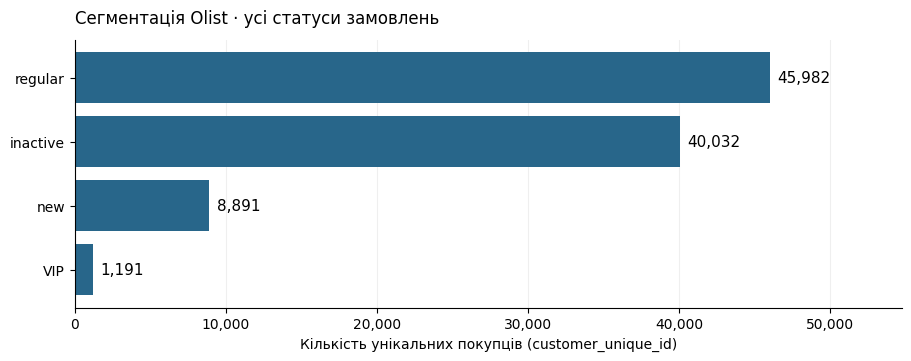

In [23]:
import matplotlib.pyplot as plt
from matplotlib.ticker import StrMethodFormatter
segment_rows=results["16_segments_summary"]["rows"]
fig,ax=plt.subplots(figsize=(9,3.5),layout="constrained")
labels=[r["segment_name"] for r in segment_rows][::-1]
values=[r["n_buyers"] for r in segment_rows][::-1]
ax.barh(labels,values,color="#28668a")
for index,value in enumerate(values): ax.text(value+500,index,f"{value:,}",va="center",fontsize=11)
ax.set_xlim(0,max(values)*1.19)
ax.set_title("Сегментація Olist · усі статуси замовлень",loc="left",pad=12)
ax.set_xlabel("Кількість унікальних покупців (customer_unique_id)")
ax.xaxis.set_major_formatter(StrMethodFormatter("{x:,.0f}"))
ax.grid(axis="x",alpha=.2); ax.set_axisbelow(True)
ax.spines[["top","right"]].set_visible(False)
fig.savefig(WORK_DIR/"segments.png",dpi=160,bbox_inches="tight")
plt.show()
plt.close(fig)

**Висновок:** отримано 96 096 унікальних покупців: 45 982 `regular`, 40 032 `inactive`, 8 891 `new` і 1 191 `VIP`. Суми за сегментами узгоджуються з усіма 99 441 замовленнями та записаним GMV товарів із freight 15 843 553,24. Це зріз усіх статусів на `reference_date=2018-10-18`: GMV не є чистим доходом, а назва `inactive` позначає правило сегментації й не доводить відтік.

## 6. П’ять JOIN
### 6.1. INNER JOIN чотирьох таблиць
**Запитання:** які категорії та штати sellers мають найбільший GMV товарів із доставкою у delivered-замовленнях?

In [24]:
results['17_join_inner'] = run_sql('17_join_inner', "SELECT\n    p.product_category_name,\n    s.seller_state,\n    COUNT(DISTINCT oi.order_id) AS n_orders,\n    SUM(oi.price + oi.freight_value)::NUMERIC(12, 2) AS delivered_gmv\nFROM olist_order_items AS oi\nJOIN olist_orders AS o\n    ON o.order_id = oi.order_id\nJOIN olist_products AS p\n    ON p.product_id = oi.product_id\nJOIN olist_sellers AS s\n    ON s.seller_id = oi.seller_id\nWHERE o.order_status = 'delivered'\nGROUP BY p.product_category_name, s.seller_state\nORDER BY delivered_gmv DESC NULLS LAST, p.product_category_name NULLS LAST, s.seller_state\nLIMIT 10;")

```sql
SELECT
    p.product_category_name,
    s.seller_state,
    COUNT(DISTINCT oi.order_id) AS n_orders,
    SUM(oi.price + oi.freight_value)::NUMERIC(12, 2) AS delivered_gmv
FROM olist_order_items AS oi
JOIN olist_orders AS o
    ON o.order_id = oi.order_id
JOIN olist_products AS p
    ON p.product_id = oi.product_id
JOIN olist_sellers AS s
    ON s.seller_id = oi.seller_id
WHERE o.order_status = 'delivered'
GROUP BY p.product_category_name, s.seller_state
ORDER BY delivered_gmv DESC NULLS LAST, p.product_category_name NULLS LAST, s.seller_state
LIMIT 10;
```

product_category_name,seller_state,n_orders,delivered_gmv
cama_mesa_banho,SP,8214,1070048.14
relogios_presentes,SP,4494,1016168.80
beleza_saude,SP,5684,790967.66
esporte_lazer,SP,4772,680165.54
moveis_decoracao,SP,4597,605650.63
cool_stuff,SP,2621,484196.53
utilidades_domesticas,SP,4021,471810.66
automotivo,SP,3018,438833.22
informatica_acessorios,SP,2783,388506.42
bebes,SP,1981,339129.74


17_join_inner: 10 рядків.


**Висновок:** серед десяти виведених груп лідирує `cama_mesa_banho × SP`: 8 214 distinct orders і delivered-GMV 1 070 048,14. Усі десять рядків стосуються sellers зі штату SP, що показує концентрацію саме верхівки цього рейтингу, а не відсутність продажів у інших штатах. Метрика включає price і freight лише для `delivered` orders та не є чистим доходом; кількості orders між категоріями не додаються, бо одне замовлення може потрапити до кількох груп.

### 6.2. LEFT JOIN і COALESCE
**Запитання:** які фічі покупця можна зібрати, зберігши buyer навіть за відсутності частини пов’язаних даних?

In [25]:
results['18_join_left'] = run_sql('18_join_left', 'WITH order_totals AS (\n    SELECT\n        o.order_id,\n        c.customer_unique_id,\n        SUM(oi.price + oi.freight_value)::NUMERIC(12, 2) AS order_total\n    FROM olist_orders AS o\n    JOIN olist_customers AS c\n        ON c.customer_id = o.customer_id\n    LEFT JOIN olist_order_items AS oi\n        ON oi.order_id = o.order_id\n    GROUP BY\n        o.order_id,\n        c.customer_unique_id\n),\nreview_per_order AS (\n    SELECT\n        rv.order_id,\n        AVG(rv.review_score)::NUMERIC(3, 2) AS order_review_score\n    FROM olist_order_reviews AS rv\n    WHERE rv.review_score IS NOT NULL\n    GROUP BY rv.order_id\n),\ncustomer_stats AS (\n    SELECT\n        ot.customer_unique_id,\n        COUNT(DISTINCT ot.order_id) AS n_orders,\n        COALESCE(SUM(ot.order_total), 0)::NUMERIC(12, 2) AS total_spend,\n        AVG(rpo.order_review_score)::NUMERIC(3, 2) AS avg_review_score\n    FROM order_totals AS ot\n    LEFT JOIN review_per_order AS rpo\n        ON rpo.order_id = ot.order_id\n    GROUP BY ot.customer_unique_id\n)\nSELECT\n    cd.customer_unique_id,\n    cd.customer_state,\n    COALESCE(cs.n_orders, 0) AS n_orders,\n    COALESCE(cs.total_spend, 0)::NUMERIC(12, 2) AS total_spend,\n    cs.avg_review_score,\n    (cs.avg_review_score IS NULL) AS review_missing\nFROM olist_customer_dim AS cd\nLEFT JOIN customer_stats AS cs\n    ON cs.customer_unique_id = cd.customer_unique_id\nORDER BY total_spend DESC NULLS LAST, cd.customer_unique_id\nLIMIT 20;')

```sql
WITH order_totals AS (
    SELECT
        o.order_id,
        c.customer_unique_id,
        SUM(oi.price + oi.freight_value)::NUMERIC(12, 2) AS order_total
    FROM olist_orders AS o
    JOIN olist_customers AS c
        ON c.customer_id = o.customer_id
    LEFT JOIN olist_order_items AS oi
        ON oi.order_id = o.order_id
    GROUP BY
        o.order_id,
        c.customer_unique_id
),
review_per_order AS (
    SELECT
        rv.order_id,
        AVG(rv.review_score)::NUMERIC(3, 2) AS order_review_score
    FROM olist_order_reviews AS rv
    WHERE rv.review_score IS NOT NULL
    GROUP BY rv.order_id
),
customer_stats AS (
    SELECT
        ot.customer_unique_id,
        COUNT(DISTINCT ot.order_id) AS n_orders,
        COALESCE(SUM(ot.order_total), 0)::NUMERIC(12, 2) AS total_spend,
        AVG(rpo.order_review_score)::NUMERIC(3, 2) AS avg_review_score
    FROM order_totals AS ot
    LEFT JOIN review_per_order AS rpo
        ON rpo.order_id = ot.order_id
    GROUP BY ot.customer_unique_id
)
SELECT
    cd.customer_unique_id,
    cd.customer_state,
    COALESCE(cs.n_orders, 0) AS n_orders,
    COALESCE(cs.total_spend, 0)::NUMERIC(12, 2) AS total_spend,
    cs.avg_review_score,
    (cs.avg_review_score IS NULL) AS review_missing
FROM olist_customer_dim AS cd
LEFT JOIN customer_stats AS cs
    ON cs.customer_unique_id = cd.customer_unique_id
ORDER BY total_spend DESC NULLS LAST, cd.customer_unique_id
LIMIT 20;
```

customer_unique_id,customer_state,n_orders,total_spend,avg_review_score,review_missing
0a0a92112bd4c708ca5fde585afaa872,RJ,1,13664.08,1.00,False
da122df9eeddfedc1dc1f5349a1a690c,RJ,2,7571.63,5.00,False
763c8b1c9c68a0229c42c9fc6f662b93,ES,1,7274.88,1.00,False
dc4802a71eae9be1dd28f5d788ceb526,MS,1,6929.31,5.00,False
459bef486812aa25204be022145caa62,ES,1,6922.21,None,True
ff4159b92c40ebe40454e3e6a7c35ed6,SP,1,6726.66,5.00,False
4007669dec559734d6f53e029e360987,MG,1,6081.54,1.00,False
5d0a2980b292d049061542014e8960bf,GO,1,4809.44,1.00,False
eebb5dda148d3893cdaf5b5ca3040ccb,SP,1,4764.34,4.00,False
48e1ac109decbb87765a3eade6854098,PB,1,4681.78,5.00,False


18_join_left: 20 рядків.


**Висновок:** у preview 20 покупців із найбільшим записаним GMV усіх статусів перший `0a0a92112bd4c708ca5fde585afaa872` має одне замовлення, 13 664,08 з freight і середню оцінку 1,00. Для `459bef486812aa25204be022145caa62` збережено GMV 6 922,21 разом із `avg_review_score=NULL` і `review_missing=TRUE`, тому відсутність review не підмінена нульовою оцінкою. Попередні агрегати до order, а потім до `customer_unique_id` захищають суми й оцінки від множення позиціями; `LEFT JOIN` зберігає buyer, а `COALESCE` задає нулі лише для відсутніх counts і GMV.

### 6.3. FULL OUTER JOIN
**Запитання:** у яких штатах представлені тільки клієнти, тільки sellers або обидві сторони?

In [26]:
results['19_join_full'] = run_sql('19_join_full', "WITH customer_states AS (\n    SELECT customer_state AS state, COUNT(*) AS n_customers\n    FROM olist_customers\n    GROUP BY customer_state\n), seller_states AS (\n    SELECT seller_state AS state, COUNT(*) AS n_sellers\n    FROM olist_sellers\n    GROUP BY seller_state\n)\nSELECT\n    COALESCE(c.state, s.state) AS state,\n    c.n_customers,\n    s.n_sellers,\n    CASE\n        WHEN c.state IS NOT NULL AND s.state IS NOT NULL THEN 'both'\n        WHEN c.state IS NOT NULL THEN 'customers_only'\n        ELSE 'sellers_only'\n    END AS state_presence\nFROM customer_states AS c\nFULL OUTER JOIN seller_states AS s\n    ON s.state = c.state\nORDER BY state;")

```sql
WITH customer_states AS (
    SELECT customer_state AS state, COUNT(*) AS n_customers
    FROM olist_customers
    GROUP BY customer_state
), seller_states AS (
    SELECT seller_state AS state, COUNT(*) AS n_sellers
    FROM olist_sellers
    GROUP BY seller_state
)
SELECT
    COALESCE(c.state, s.state) AS state,
    c.n_customers,
    s.n_sellers,
    CASE
        WHEN c.state IS NOT NULL AND s.state IS NOT NULL THEN 'both'
        WHEN c.state IS NOT NULL THEN 'customers_only'
        ELSE 'sellers_only'
    END AS state_presence
FROM customer_states AS c
FULL OUTER JOIN seller_states AS s
    ON s.state = c.state
ORDER BY state;
```

state,n_customers,n_sellers,state_presence
AC,81,1.0,both
AL,413,NULL,customers_only
AM,148,1.0,both
AP,68,NULL,customers_only
BA,3380,19.0,both
CE,1336,13.0,both
DF,2140,30.0,both
ES,2033,23.0,both
GO,2020,40.0,both
MA,747,1.0,both


19_join_full: 27 рядків.


**Висновок:** повний результат містить 27 state-кодів: 23 представлені з обох боків, AL/AP/RR/TO — лише серед customers, а seller-only штатів немає. Найбільші counts має SP: 41 746 customer-записів і 1 849 sellers. `n_customers` рахує `customer_id`, а не реальних buyers; попередня агрегація до state запобігає множенню customers × sellers, а `NULL` праворуч позначає відсутній штат у seller-наборі.

### 6.4. SELF JOIN
**Запитання:** які пари sellers з одного штату й різних міст можна розглянути для регіонального порівняння?

In [27]:
results['20_join_self'] = run_sql('20_join_self', 'SELECT\n    s1.seller_id AS seller_a,\n    s2.seller_id AS seller_b,\n    s1.seller_state,\n    s1.seller_city AS city_a,\n    s2.seller_city AS city_b\nFROM olist_sellers AS s1\nJOIN olist_sellers AS s2\n    ON s1.seller_state = s2.seller_state\n   AND s1.seller_id < s2.seller_id\n   AND s1.seller_city IS DISTINCT FROM s2.seller_city\nORDER BY s1.seller_state, seller_a, seller_b\nLIMIT 20;')

```sql
SELECT
    s1.seller_id AS seller_a,
    s2.seller_id AS seller_b,
    s1.seller_state,
    s1.seller_city AS city_a,
    s2.seller_city AS city_b
FROM olist_sellers AS s1
JOIN olist_sellers AS s2
    ON s1.seller_state = s2.seller_state
   AND s1.seller_id < s2.seller_id
   AND s1.seller_city IS DISTINCT FROM s2.seller_city
ORDER BY s1.seller_state, seller_a, seller_b
LIMIT 20;
```

seller_a,seller_b,seller_state,city_a,city_b
1444c08e64d55fb3c25f0f09c07ffcf2,2b402d5dc42554061f8ea98d1916f148,BA,lauro de freitas,irece
1444c08e64d55fb3c25f0f09c07ffcf2,398cb257329ef7af7f1943a8974a3cbc,BA,lauro de freitas,salvador
1444c08e64d55fb3c25f0f09c07ffcf2,4221a7df464f1fe2955934e30ff3a5a1,BA,lauro de freitas,bahia
1444c08e64d55fb3c25f0f09c07ffcf2,43753b27d77860f1654aa72e251a7878,BA,lauro de freitas,barro alto
1444c08e64d55fb3c25f0f09c07ffcf2,4aba391bc3b88717ce08eb11e44937b2,BA,lauro de freitas,arraial d'ajuda (porto seguro)
1444c08e64d55fb3c25f0f09c07ffcf2,4fb41dff7c50136976d1a5cf004a42e2,BA,lauro de freitas,feira de santana
1444c08e64d55fb3c25f0f09c07ffcf2,651530bf5c607240ccdd89a30c9c9712,BA,lauro de freitas,ipira
1444c08e64d55fb3c25f0f09c07ffcf2,659e8466eb3ff1b0e8740d74fb7bbedd,BA,lauro de freitas,eunapolis
1444c08e64d55fb3c25f0f09c07ffcf2,75d34ebb1bd0bd7dde40dd507b8169c3,BA,lauro de freitas,salvador
1444c08e64d55fb3c25f0f09c07ffcf2,a3dd39f583bc80bd8c5901c95878921e,BA,lauro de freitas,salvador


20_join_self: 20 рядків.


**Висновок:** усі 20 показаних кандидатних пар належать штату BA; перша поєднує sellers із `lauro de freitas` та `irece`. Умова `seller_a < seller_b` виключає самопари й дзеркальні дублікати, а `IS DISTINCT FROM` порівнює міста з урахуванням можливих NULL. Це preview, упорядкований за state та ID, тому він не є рейтингом ефективності й не доводить, що ці sellers мають порівнюваний асортимент або масштаби.

### 6.5. Anti-join
**Запитання:** які orders не мають жодного review-запису, щоб не трактувати відсутність оцінки як незадоволення?

In [28]:
results['21_join_anti'] = run_sql('21_join_anti', 'SELECT\n    o.order_id,\n    o.customer_id,\n    o.order_status,\n    o.order_purchase_timestamp\nFROM olist_orders AS o\nLEFT JOIN olist_order_reviews AS rv\n    ON rv.order_id = o.order_id\nWHERE rv.review_row_id IS NULL\nORDER BY o.order_purchase_timestamp, o.order_id\nLIMIT 20;')

```sql
SELECT
    o.order_id,
    o.customer_id,
    o.order_status,
    o.order_purchase_timestamp
FROM olist_orders AS o
LEFT JOIN olist_order_reviews AS rv
    ON rv.order_id = o.order_id
WHERE rv.review_row_id IS NULL
ORDER BY o.order_purchase_timestamp, o.order_id
LIMIT 20;
```

order_id,customer_id,order_status,order_purchase_timestamp
cda873529ca7ab71f677d5ec11a40304,76c74aaff2f3f7355f46d9818ad092b8,shipped,2016-10-05 16:57:30
5da2004d85f2828349d887c989da2adc,95f592086150f0c95d3082aea047b816,delivered,2016-10-05 20:20:59
02190241f7190a1f3c7e0df95a749c6a,55c9044401ffab0c717f24405e2e042f,delivered,2016-10-07 10:52:22
0efd0bc268d34da3f01f4ff25a6d4335,95446917717bb58d553d107d0f1668f6,shipped,2016-10-07 15:53:31
c776863a93dc0740c6e7d78104b21413,1710b798ebdc5db6665c815b90a64999,delivered,2016-10-10 15:01:27
d730d8d0ea3149120703933fdf98b2d4,ce2a66464da8b80dedd7639a6e489a58,shipped,2017-01-13 20:12:41
05cd156f0f47579a36d7a52724fc31b8,976224a95faf328b17654b1b1411d5e1,delivered,2017-01-14 18:27:28
719b940ab2f1e351ffb14a0a02ffe3c4,ede9a1daf58d256c0d648ef7e1479010,delivered,2017-01-16 13:01:51
fbd82b1fe98967de0db29b6cf134d00a,45f5c9d984dbfa2105e3544cc85133bf,delivered,2017-01-18 08:55:36
171398a0cd843c65ac78aee9e05a1f49,f0244902c07b7c0799e468218579a925,delivered,2017-01-18 16:07:37


21_join_anti: 20 рядків.


**Висновок:** аудит нарахував 768 orders без review, а цей запит показує 20 найраніших; перший має статус `shipped` і дату покупки 2016-10-05 16:57:30. У preview є також `delivered` orders, тому відсутність відгуку не зводиться лише до незавершених замовлень і сама по собі не означає невдоволення. Перевірка `review_row_id IS NULL` використовує гарантовано непорожній технічний PK правої таблиці та виділяє саме відсутність будь-якого review-запису.

## 7. GROUP BY, HAVING та агрегати
### 7.1. GMV за категоріями
**Запитання:** які категорії мають суму записаних цін товарів понад 10 000? Усі статуси, freight окремо; `avg_item_price` має зерно позиції. `HAVING` фільтрує вже обчислені групи; якби додати `WHERE order_status='delivered'` через JOIN orders, він би відфільтрував вихідні рядки до SUM.

In [29]:
results['22_aggregate_category'] = run_sql('22_aggregate_category', 'SELECT\n    p.product_category_name,\n    COUNT(DISTINCT oi.order_id) AS n_orders,\n    SUM(oi.price)::NUMERIC(12, 2) AS merchandise_gmv,\n    SUM(oi.freight_value)::NUMERIC(12, 2) AS freight,\n    AVG(oi.price)::NUMERIC(8, 2) AS avg_item_price\nFROM olist_order_items AS oi\nJOIN olist_products AS p\n    ON p.product_id = oi.product_id\nGROUP BY p.product_category_name\nHAVING SUM(oi.price) > 10000\nORDER BY merchandise_gmv DESC NULLS LAST, p.product_category_name NULLS LAST;')

```sql
SELECT
    p.product_category_name,
    COUNT(DISTINCT oi.order_id) AS n_orders,
    SUM(oi.price)::NUMERIC(12, 2) AS merchandise_gmv,
    SUM(oi.freight_value)::NUMERIC(12, 2) AS freight,
    AVG(oi.price)::NUMERIC(8, 2) AS avg_item_price
FROM olist_order_items AS oi
JOIN olist_products AS p
    ON p.product_id = oi.product_id
GROUP BY p.product_category_name
HAVING SUM(oi.price) > 10000
ORDER BY merchandise_gmv DESC NULLS LAST, p.product_category_name NULLS LAST;
```

product_category_name,n_orders,merchandise_gmv,freight,avg_item_price
beleza_saude,8836,1258681.34,182566.73,130.16
relogios_presentes,5624,1205005.68,100535.93,201.14
cama_mesa_banho,9417,1036988.68,204693.04,93.30
esporte_lazer,7720,988048.97,168607.51,114.34
informatica_acessorios,6689,911954.32,147318.08,116.51
moveis_decoracao,6449,729762.49,172749.30,87.56
cool_stuff,3632,635290.85,84039.10,167.36
utilidades_domesticas,5884,632248.66,146149.11,90.79
automotivo,3897,592720.11,92664.21,139.96
ferramentas_jardim,3518,485256.46,98962.75,111.63


22_aggregate_category: 53 рядків; показано перші 10, це preview.


**Висновок:** поріг `HAVING SUM(price)>10000` пройшли 53 групи; серед десяти показаних рядків лідирує `beleza_saude` з merchandise-GMV 1 258 681,34 та окремим freight 182 566,73. Її `avg_item_price=130,16` є середнім за позиціями, тоді як 8 836 distinct orders рахуються на рівні замовлення в цій категорії. Запит враховує всі статуси, а merchandise-GMV містить лише ціни товарів, тому його не слід трактувати як чистий дохід або безпосередньо порівнювати з delivered-GMV, що включає freight.

### 7.2. AOV за штатом покупця
**Запитання:** як відрізняється середній GMV на замовлення серед штатів із ≥100 замовлень з позиціями? CTE спочатку дає один рядок на order, тому AOV не стає середнім за позиціями. Враховані всі статуси; orders без items не входять у цей знаменник.

In [30]:
results['23_aggregate_state'] = run_sql('23_aggregate_state', 'WITH order_totals AS (\n    SELECT\n        o.order_id,\n        c.customer_state,\n        SUM(oi.price + oi.freight_value)::NUMERIC(12, 2) AS order_total\n    FROM olist_orders AS o\n    JOIN olist_customers AS c\n        ON c.customer_id = o.customer_id\n    JOIN olist_order_items AS oi\n        ON oi.order_id = o.order_id\n    GROUP BY\n        o.order_id,\n        c.customer_state\n)\nSELECT\n    customer_state,\n    COUNT(*) AS n_orders,\n    SUM(order_total)::NUMERIC(12, 2) AS gmv,\n    (SUM(order_total) / NULLIF(COUNT(*), 0))::NUMERIC(8, 2) AS aov\nFROM order_totals\nGROUP BY customer_state\nHAVING COUNT(*) >= 100\nORDER BY aov DESC NULLS LAST, customer_state;')

```sql
WITH order_totals AS (
    SELECT
        o.order_id,
        c.customer_state,
        SUM(oi.price + oi.freight_value)::NUMERIC(12, 2) AS order_total
    FROM olist_orders AS o
    JOIN olist_customers AS c
        ON c.customer_id = o.customer_id
    JOIN olist_order_items AS oi
        ON oi.order_id = o.order_id
    GROUP BY
        o.order_id,
        c.customer_state
)
SELECT
    customer_state,
    COUNT(*) AS n_orders,
    SUM(order_total)::NUMERIC(12, 2) AS gmv,
    (SUM(order_total) / NULLIF(COUNT(*), 0))::NUMERIC(8, 2) AS aov
FROM order_totals
GROUP BY customer_state
HAVING COUNT(*) >= 100
ORDER BY aov DESC NULLS LAST, customer_state;
```

customer_state,n_orders,gmv,aov
PB,532,140987.81,265.01
AL,411,96229.40,234.13
RO,247,57558.02,233.03
PA,970,217647.11,224.38
TO,279,61354.42,219.91
PI,493,108132.28,219.34
SE,345,73032.32,211.69
RN,482,101895.08,211.40
CE,1327,275606.30,207.69
MT,903,186168.96,206.17


23_aggregate_state: 24 рядків.


**Висновок:** умову щонайменше 100 orders із позиціями виконали 24 штати; найбільший AOV має PB — 265,01 на 532 замовленнях. У SP AOV становить 143,12 на 41 375 замовленнях, отже найбільша кількість orders не означає найвищий середній чек у цьому зрізі. AOV обчислено після агрегації позицій до order і включає freight та всі статуси; 775 orders без items не входять у знаменник, а відмінності між штатами не встановлюють причин.

### 7.3. Категорії buyer через STRING_AGG
**Запитання:** які категорії присутні в покупках buyers із найбільшим merchandise-GMV? `STRING_AGG(DISTINCT ... ORDER BY ...)` прибирає повторні назви та стабілізує їх порядок. `(unknown)` зберігає інформацію про пропущені категорії; freight не входить у `total_spend`.

In [31]:
results['24_aggregate_buyer_categories'] = run_sql('24_aggregate_buyer_categories', "SELECT\n    c.customer_unique_id,\n    COUNT(DISTINCT o.order_id) AS n_orders,\n    SUM(oi.price)::NUMERIC(12, 2) AS total_spend,\n    STRING_AGG(\n        DISTINCT COALESCE(p.product_category_name, '(unknown)'),\n        ', ' ORDER BY COALESCE(p.product_category_name, '(unknown)')\n    ) AS categories\nFROM olist_customers AS c\nJOIN olist_orders AS o\n    ON o.customer_id = c.customer_id\nJOIN olist_order_items AS oi\n    ON oi.order_id = o.order_id\nLEFT JOIN olist_products AS p\n    ON p.product_id = oi.product_id\nGROUP BY c.customer_unique_id\nHAVING COUNT(DISTINCT o.order_id) >= 1\nORDER BY total_spend DESC NULLS LAST, c.customer_unique_id\nLIMIT 20;")

```sql
SELECT
    c.customer_unique_id,
    COUNT(DISTINCT o.order_id) AS n_orders,
    SUM(oi.price)::NUMERIC(12, 2) AS total_spend,
    STRING_AGG(
        DISTINCT COALESCE(p.product_category_name, '(unknown)'),
        ', ' ORDER BY COALESCE(p.product_category_name, '(unknown)')
    ) AS categories
FROM olist_customers AS c
JOIN olist_orders AS o
    ON o.customer_id = c.customer_id
JOIN olist_order_items AS oi
    ON oi.order_id = o.order_id
LEFT JOIN olist_products AS p
    ON p.product_id = oi.product_id
GROUP BY c.customer_unique_id
HAVING COUNT(DISTINCT o.order_id) >= 1
ORDER BY total_spend DESC NULLS LAST, c.customer_unique_id
LIMIT 20;
```

customer_unique_id,n_orders,total_spend,categories
0a0a92112bd4c708ca5fde585afaa872,1,13440.00,telefonia_fixa
da122df9eeddfedc1dc1f5349a1a690c,2,7388.00,eletroportateis
763c8b1c9c68a0229c42c9fc6f662b93,1,7160.00,telefonia_fixa
dc4802a71eae9be1dd28f5d788ceb526,1,6735.00,utilidades_domesticas
459bef486812aa25204be022145caa62,1,6729.00,pcs
ff4159b92c40ebe40454e3e6a7c35ed6,1,6499.00,artes
4007669dec559734d6f53e029e360987,1,5934.60,agro_industria_e_comercio
eebb5dda148d3893cdaf5b5ca3040ccb,1,4690.00,eletroportateis
5d0a2980b292d049061542014e8960bf,1,4599.90,cool_stuff
48e1ac109decbb87765a3eade6854098,1,4590.00,pcs


24_aggregate_buyer_categories: 20 рядків.


**Висновок:** серед 20 buyers із найбільшою сумою цін товарів лідирує `0a0a92112bd4c708ca5fde585afaa872`: одне замовлення, 13 440,00 та категорія `telefonia_fixa`. Для `5e713be0853d8986528d7869a0811d2b` сума 3 980,00 збережена разом із `(unknown)`, тож пропущена категорія не видаляє buyer з результату. `STRING_AGG(DISTINCT … ORDER BY …)` дає стабільний список неповторних категорій на `customer_unique_id`; сума враховує всі статуси, виключає freight і не є чистим доходом, а використання фічі в ML потребує часового cutoff.

## 8. Set operation і window function
### 8.1. INTERSECT
**Запитання:** які state-коди одночасно представлені в customers і sellers? `INTERSECT` повертає унікальний перетин; дублікати вихідних state не потрібні.

In [32]:
results['25_set_intersect'] = run_sql('25_set_intersect', 'SELECT customer_state AS state\nFROM olist_customers\n\nINTERSECT\n\nSELECT seller_state AS state\nFROM olist_sellers\nORDER BY state;')

```sql
SELECT customer_state AS state
FROM olist_customers

INTERSECT

SELECT seller_state AS state
FROM olist_sellers
ORDER BY state;
```

state
AC
AM
BA
CE
DF
ES
GO
MA
MG
MS


25_set_intersect: 23 рядків.


**Висновок:** `INTERSECT` повернув 23 унікальні state-коди, присутні одночасно в customers і sellers. AL/AP/RR/TO відсутні в цьому результаті, що узгоджується з їхнім `customers_only` у FULL OUTER JOIN. Оператор обрано для унікального перетину двох наборів: він перевіряє спільну географічну присутність, але не доводить, що клієнти купували саме у sellers зі свого штату.

### 8.2. ROW_NUMBER
**Запитання:** яке останнє замовлення кожного реального buyer для фіч на історичному зрізі? `PARTITION BY customer_unique_id`, timestamp DESC та order_id DESC задають однозначний вибір. Для production ML зріз потрібно обмежувати моментом прогнозу, щоб не додати майбутні події.

In [33]:
results['26_window_latest'] = run_sql('26_window_latest', 'WITH ranked_orders AS (\n    SELECT\n        c.customer_unique_id,\n        o.customer_id,\n        o.order_id,\n        o.order_purchase_timestamp,\n        ROW_NUMBER() OVER (\n            PARTITION BY c.customer_unique_id\n            ORDER BY o.order_purchase_timestamp DESC, o.order_id DESC\n        ) AS rn\n    FROM olist_orders AS o\n    JOIN olist_customers AS c\n        ON c.customer_id = o.customer_id\n)\nSELECT\n    customer_unique_id,\n    customer_id,\n    order_id,\n    order_purchase_timestamp\nFROM ranked_orders\nWHERE rn = 1\nORDER BY customer_unique_id\nLIMIT 20;')

```sql
WITH ranked_orders AS (
    SELECT
        c.customer_unique_id,
        o.customer_id,
        o.order_id,
        o.order_purchase_timestamp,
        ROW_NUMBER() OVER (
            PARTITION BY c.customer_unique_id
            ORDER BY o.order_purchase_timestamp DESC, o.order_id DESC
        ) AS rn
    FROM olist_orders AS o
    JOIN olist_customers AS c
        ON c.customer_id = o.customer_id
)
SELECT
    customer_unique_id,
    customer_id,
    order_id,
    order_purchase_timestamp
FROM ranked_orders
WHERE rn = 1
ORDER BY customer_unique_id
LIMIT 20;
```

customer_unique_id,customer_id,order_id,order_purchase_timestamp
0000366f3b9a7992bf8c76cfdf3221e2,fadbb3709178fc513abc1b2670aa1ad2,e22acc9c116caa3f2b7121bbb380d08e,2018-05-10 10:56:27
0000b849f77a49e4a4ce2b2a4ca5be3f,4cb282e167ae9234755102258dd52ee8,3594e05a005ac4d06a72673270ef9ec9,2018-05-07 11:11:27
0000f46a3911fa3c0805444483337064,9b3932a6253894a02c1df9d19004239f,b33ec3b699337181488304f362a6b734,2017-03-10 21:05:03
0000f6ccb0745a6a4b88665a16c9f078,914991f0c02ef0843c0e7010c819d642,41272756ecddd9a9ed0180413cc22fb6,2017-10-12 20:29:41
0004aac84e0df4da2b147fca70cf8255,47227568b10f5f58a524a75507e6992c,d957021f1127559cd947b62533f484f7,2017-11-14 19:45:42
0004bd2a26a76fe21f786e4fbd80607f,4a913a170c26e3c8052ed0202849b5a8,3e470077b690ea3e3d501cffb5e0c499,2018-04-05 19:33:16
00050ab1314c0e55a6ca13cf7181fecf,d2509c13692836fc0449e88cf9eb4858,d0028facea13f508e880202d7097a5a1,2018-04-20 12:57:23
00053a61a98854899e70ed204dd4bafe,a81ebb9b32f102298c0c89635b4b3154,44e608f2db00c74a1fe329de44416a4e,2018-02-28 11:15:41
0005e1862207bf6ccc02e4228effd9a0,3b37fb626fdf46cd99d37ec62afa88ff,ae76bef74b97bcb0b3e355e60d9a6f9c,2017-03-04 23:32:12
0005ef4cd20d2893f0d9fbd94d3c0d97,c59e8ff99836e90d8b457d4122dc34e9,01b330808c5819a6a3cb79b72f0b8288,2018-03-12 15:22:12


26_window_latest: 20 рядків.


**Висновок:** preview містить останнє замовлення для перших 20 `customer_unique_id` у лексикографічному порядку; для `0000366f3b9a7992bf8c76cfdf3221e2` це `e22acc9c116caa3f2b7121bbb380d08e` від 2018-05-10 10:56:27. `ROW_NUMBER` ранжує orders усередині buyer за спаданням timestamp, а `order_id DESC` однозначно розв’язує часові ties перед зовнішнім фільтром `rn=1`. Вибір охоплює всі статуси й усю доступну історію, тому для прогнозної ML-фічі спочатку потрібне обмеження подій моментом прогнозу.

## 9. Перевірки зерна, constraints та повторення
Перевірки нижче контролюють повноту імпорту, grain LEFT/FULL/anti-join, бізнесову ідемпотентність DML і негативні випадки. Два upsert виконуються ще раз навмисно; порівнюються бізнес-колонки без технічних timestamp/identity. Негативні INSERT відкотяться до SAVEPOINT.

In [34]:
checks={}
repeat_sql={'07_insert_alert': "WITH seller_orders AS (\n    SELECT DISTINCT\n        oi.seller_id,\n        oi.order_id\n    FROM olist_order_items AS oi\n),\nlate_sellers AS (\n    SELECT\n        so.seller_id,\n        COUNT(DISTINCT o.order_id) AS late_orders\n    FROM seller_orders AS so\n    JOIN olist_orders AS o\n        ON o.order_id = so.order_id\n    WHERE o.order_delivered_customer_date IS NOT NULL\n      AND o.order_estimated_delivery_date IS NOT NULL\n      AND o.order_delivered_customer_date::DATE > o.order_estimated_delivery_date::DATE\n    GROUP BY so.seller_id\n    ORDER BY late_orders DESC, so.seller_id\n    LIMIT 1\n)\nINSERT INTO hw4_seller_alerts (seller_id, alert_type, severity, details)\nSELECT\n    seller_id,\n    'late_delivery',\n    4,\n    'Seller has ' || late_orders || ' late delivered orders in the loaded dataset'\nFROM late_sellers AS ls\nWHERE NOT EXISTS (\n    SELECT 1 FROM hw4_seller_alerts AS a\n    WHERE a.seller_id = ls.seller_id AND a.alert_type = 'late_delivery'\n)\nRETURNING alert_id, seller_id, alert_type, severity, created_at;", '08_upsert_score': "WITH seller_orders AS (\n    SELECT DISTINCT\n        oi.seller_id,\n        oi.order_id\n    FROM olist_order_items AS oi\n),\nreview_per_order AS (\n    SELECT\n        rv.order_id,\n        AVG(rv.review_score)::NUMERIC(3, 2) AS order_review_score\n    FROM olist_order_reviews AS rv\n    WHERE rv.review_score IS NOT NULL\n    GROUP BY rv.order_id\n),\nseller_rating AS (\n    SELECT\n        so.seller_id,\n        AVG(rpo.order_review_score)::NUMERIC(3, 2) AS avg_rating,\n        COUNT(rpo.order_id) AS n_reviews\n    FROM seller_orders AS so\n    LEFT JOIN review_per_order AS rpo\n        ON rpo.order_id = so.order_id\n    GROUP BY so.seller_id\n)\nINSERT INTO hw4_seller_score (seller_id, avg_rating, n_reviews, tier)\nSELECT\n    seller_id,\n    avg_rating,\n    n_reviews,\n    CASE\n        WHEN avg_rating IS NULL THEN NULL\n        WHEN avg_rating >= 4.5 THEN 'gold'\n        WHEN avg_rating >= 3.5 THEN 'silver'\n        ELSE 'bronze'\n    END AS tier\nFROM seller_rating\nON CONFLICT (seller_id) DO UPDATE\nSET avg_rating = EXCLUDED.avg_rating,\n    n_reviews  = EXCLUDED.n_reviews,\n    tier       = EXCLUDED.tier,\n    updated_at = NOW()\nRETURNING seller_id, avg_rating, n_reviews, tier, updated_at;", '10_update_late': 'WITH delivery_flags AS (\n    SELECT\n        order_id,\n        (\n            order_delivered_customer_date IS NOT NULL\n            AND order_estimated_delivery_date IS NOT NULL\n            AND order_delivered_customer_date::DATE > order_estimated_delivery_date::DATE\n        ) AS is_late_calc\n    FROM olist_orders\n)\nUPDATE olist_orders AS o\nSET is_late = f.is_late_calc\nFROM delivery_flags AS f\nWHERE f.order_id = o.order_id\nRETURNING o.order_id, o.customer_id, o.is_late;', '11_delete_alert': "DELETE FROM hw4_seller_alerts\nWHERE created_at < NOW() - INTERVAL '30 days'\nRETURNING alert_id, seller_id, alert_type, created_at;", '14_upsert_segments': "WITH reference_date AS (\n    SELECT (MAX(order_purchase_timestamp)::DATE + 1) AS as_of_date\n    FROM olist_orders\n),\norder_totals AS (\n    SELECT\n        o.order_id,\n        o.customer_id,\n        o.order_purchase_timestamp::DATE AS order_date,\n        COALESCE(SUM(oi.price + oi.freight_value), 0)::NUMERIC(12, 2) AS order_total\n    FROM olist_orders AS o\n    LEFT JOIN olist_order_items AS oi\n        ON oi.order_id = o.order_id\n    GROUP BY\n        o.order_id,\n        o.customer_id,\n        o.order_purchase_timestamp\n),\ncustomer_stats AS (\n    SELECT\n        c.customer_unique_id,\n        COUNT(DISTINCT ot.order_id) AS n_orders,\n        COALESCE(SUM(ot.order_total), 0)::NUMERIC(12, 2) AS monetary_value,\n        MAX(ot.order_date) AS last_order_date\n    FROM olist_customer_dim AS cd\n    JOIN olist_customers AS c\n        ON c.customer_unique_id = cd.customer_unique_id\n    LEFT JOIN order_totals AS ot\n        ON ot.customer_id = c.customer_id\n    GROUP BY c.customer_unique_id\n),\nsegmented AS (\n    SELECT\n        cs.customer_unique_id,\n        cs.n_orders,\n        cs.monetary_value,\n        CASE\n            WHEN cs.last_order_date IS NULL THEN NULL\n            ELSE (rd.as_of_date - cs.last_order_date)::INTEGER\n        END AS recency_days,\n        CASE\n            WHEN cs.monetary_value >= 1000 THEN 'VIP'\n            WHEN cs.last_order_date IS NOT NULL\n                 AND (rd.as_of_date - cs.last_order_date)::INTEGER <= 90\n                 AND cs.n_orders = 1 THEN 'new'\n            WHEN cs.n_orders >= 2 OR cs.monetary_value >= 100 THEN 'regular'\n            ELSE 'inactive'\n        END AS segment_name,\n        CASE\n            WHEN cs.monetary_value >= 1000 THEN 5\n            WHEN cs.monetary_value >= 500  THEN 4\n            WHEN cs.n_orders >= 2          THEN 3\n            WHEN cs.n_orders = 1           THEN 2\n            ELSE 1\n        END::SMALLINT AS rfm_score\n    FROM customer_stats AS cs\n    CROSS JOIN reference_date AS rd\n)\nINSERT INTO hw4_customer_segments (\n    customer_unique_id,\n    segment_name,\n    rfm_score,\n    recency_days,\n    monetary_value,\n    n_orders\n)\nSELECT\n    customer_unique_id,\n    segment_name,\n    rfm_score,\n    recency_days,\n    monetary_value,\n    n_orders\nFROM segmented\nON CONFLICT (customer_unique_id) DO UPDATE\nSET segment_name   = EXCLUDED.segment_name,\n    rfm_score      = EXCLUDED.rfm_score,\n    recency_days   = EXCLUDED.recency_days,\n    monetary_value = EXCLUDED.monetary_value,\n    n_orders       = EXCLUDED.n_orders,\n    assigned_at    = NOW()\nRETURNING\n    customer_unique_id,\n    segment_name,\n    rfm_score,\n    recency_days,\n    monetary_value,\n    n_orders;"}
counts={r["table_name"]:(r["raw_rows"],r["typed_rows"]) for r in results["04_counts"]["rows"]}
assert len(counts)==6 and all(a==b for a,b in counts.values())
checks["all_raw_typed_rows_preserved"]=True
assert scalar("SELECT COUNT(*) FROM olist_order_reviews")==FILES["order_reviews"]["rows_excluding_header"]
assert scalar("SELECT COUNT(*) FROM olist_customer_dim")==scalar("SELECT COUNT(DISTINCT customer_unique_id) FROM olist_customers")
assert scalar("SELECT COUNT(*) FROM hw4_customer_segments")==scalar("SELECT COUNT(*) FROM olist_customer_dim")
assert scalar("SELECT SUM(n_orders) FROM hw4_customer_segments")==scalar("SELECT COUNT(*) FROM olist_orders")
assert scalar("SELECT SUM(monetary_value) FROM hw4_customer_segments")==scalar("SELECT SUM(price+freight_value) FROM olist_order_items")
checks["buyer_grain_and_totals_reconcile"]=True
# A LEFT JOIN of the dimension to a one-row-per-buyer aggregate retains exactly its grain.
assert scalar("""WITH features AS (
 SELECT c.customer_unique_id, COUNT(DISTINCT o.order_id) n
 FROM olist_customers c LEFT JOIN olist_orders o USING (customer_id)
 GROUP BY c.customer_unique_id)
 SELECT COUNT(*) FROM olist_customer_dim d LEFT JOIN features f USING(customer_unique_id)""")==scalar("SELECT COUNT(*) FROM olist_customer_dim")
checks["left_join_retains_dimension_grain"]=True
anti_left=scalar("SELECT COUNT(*) FROM olist_orders o LEFT JOIN olist_order_reviews r USING(order_id) WHERE r.review_row_id IS NULL")
anti_exists=scalar("SELECT COUNT(*) FROM olist_orders o WHERE NOT EXISTS(SELECT 1 FROM olist_order_reviews r WHERE r.order_id=o.order_id)")
assert anti_left==anti_exists==results["05_quality"]["rows"][0]["orders_without_review"]
checks["anti_join_matches_not_exists"]=int(anti_left)
full_rows=results["19_join_full"]["rows"]
assert len({r["state"] for r in full_rows})==len(full_rows)
assert sum(r["n_customers"] or 0 for r in full_rows)==scalar("SELECT COUNT(*) FROM olist_customers")
assert sum(r["n_sellers"] or 0 for r in full_rows)==scalar("SELECT COUNT(*) FROM olist_sellers")
assert {r["state"] for r in full_rows if r["state_presence"]=="both"}=={r["state"] for r in results["25_set_intersect"]["rows"]}
checks["full_outer_grain_totals_and_intersect"]=True
assert scalar("SELECT COUNT(*) FROM pg_constraint c JOIN pg_class t ON t.oid=c.conrelid JOIN pg_namespace n ON n.oid=t.relnamespace WHERE n.nspname='hw4' AND NOT c.convalidated")==0
checks["all_constraints_validated"]=True

def business_signature(table,columns,key):
    with engine.connect() as conn:
        return list(conn.execute(text(f"SELECT {columns} FROM {table} ORDER BY {key}")))
score_before=business_signature("hw4_seller_score","seller_id,avg_rating,n_reviews,tier","seller_id")
segments_before=business_signature("hw4_customer_segments","customer_unique_id,segment_name,rfm_score,recency_days,monetary_value,n_orders","customer_unique_id")
late_before=business_signature("olist_orders","order_id,is_late","order_id")
alert_before=scalar("SELECT COUNT(*) FROM hw4_seller_alerts")
for statement in repeat_sql.values():
    with engine.begin() as conn: conn.execute(text(statement))
assert score_before==business_signature("hw4_seller_score","seller_id,avg_rating,n_reviews,tier","seller_id")
assert segments_before==business_signature("hw4_customer_segments","customer_unique_id,segment_name,rfm_score,recency_days,monetary_value,n_orders","customer_unique_id")
assert late_before==business_signature("olist_orders","order_id,is_late","order_id")
assert alert_before==scalar("SELECT COUNT(*) FROM hw4_seller_alerts")
checks["repeated_dml_business_values_unchanged"]=True
# Hand-built case: order A has two items and review scores 1,3; order B has one item and score 5.
# Each order gets equal weight: ((1+3)/2 + 5)/2 = 3.5, n_reviewed_orders=2.
fixture_sql="""WITH items(seller_id,order_id,item_id) AS (VALUES ('S','A',1),('S','A',2),('S','B',1)),
reviews(order_id,score) AS (VALUES ('A',1),('A',3),('B',5)),
so AS (SELECT DISTINCT seller_id,order_id FROM items),
rpo AS (SELECT order_id,AVG(score) score FROM reviews GROUP BY order_id)
SELECT AVG(rpo.score) FROM so JOIN rpo USING(order_id)"""
assert scalar(fixture_sql)==Decimal("3.5")
checks["hand_fixture_order_weighting"]=True
from sqlalchemy.exc import DBAPIError
negative_cases={
 "check":("INSERT INTO hw4_customer_segments(customer_unique_id,segment_name,rfm_score) SELECT customer_unique_id,'INVALID',1 FROM olist_customer_dim LIMIT 1","23514"),
 "foreign_key":("INSERT INTO hw4_customer_segments(customer_unique_id,segment_name,rfm_score) VALUES ('__absent_buyer__','new',1)","23503"),
 "not_null":("INSERT INTO hw4_customer_segments(customer_unique_id,segment_name,rfm_score) VALUES (NULL,'new',1)","23502"),
 "unique":("INSERT INTO hw4_customer_segments(customer_unique_id,segment_name,rfm_score) SELECT customer_unique_id,'new',1 FROM hw4_customer_segments LIMIT 1","23505"),
 "identity":("INSERT INTO hw4_customer_segments(segment_id,customer_unique_id,segment_name,rfm_score) VALUES (1,'__absent_buyer__','new',1)","428C9"),
}
with engine.begin() as conn:
    for label,(statement,expected_state) in negative_cases.items():
        savepoint=conn.begin_nested()
        try: conn.execute(text(statement))
        except DBAPIError as error:
            actual=error.orig.pgcode; savepoint.rollback()
            assert actual==expected_state,(label,actual,expected_state)
            checks["reject_"+label]=actual
        else:
            savepoint.rollback(); raise AssertionError("Constraint не відхилив "+label)
business_contracts={}
for label,(table,columns,key) in {
    "seller_score":("hw4_seller_score","seller_id,avg_rating,n_reviews,tier","seller_id"),
    "customer_segments":("hw4_customer_segments","customer_unique_id,segment_name,rfm_score,recency_days,monetary_value,n_orders","customer_unique_id"),
    "customer_dim":("olist_customer_dim","customer_unique_id,latest_customer_id,customer_state,customer_city","customer_unique_id"),
}.items():
    digest=hashlib.sha256()
    with engine.connect() as conn:
        query=conn.execute(text(f"SELECT {columns} FROM {table} ORDER BY {key}"))
        for row in query.mappings():
            record={k:(str(v) if isinstance(v,Decimal) else v) for k,v in row.items()}
            digest.update((json.dumps(record,sort_keys=True,ensure_ascii=False,separators=(",",":"))+"\n").encode("utf-8"))
    business_contracts[label]=digest.hexdigest()
display(pd.DataFrame([{"check":k,"result":v} for k,v in checks.items()]))
display(pd.DataFrame([{"business_table":k,"canonical_sha256":v} for k,v in business_contracts.items()]))

,check,result
0,all_raw_typed_rows_preserved,True
1,buyer_grain_and_totals_reconcile,True
2,left_join_retains_dimension_grain,True
3,anti_join_matches_not_exists,768
4,full_outer_grain_totals_and_intersect,True
5,all_constraints_validated,True
6,repeated_dml_business_values_unchanged,True
7,hand_fixture_order_weighting,True
8,reject_check,23514
9,reject_foreign_key,23503


,business_table,canonical_sha256
0,seller_score,192eaac25906c3fa402114aee11412fc577f99a34ba2d2128239061030924f98
1,customer_segments,59623e4474c5cbcd826cedb595648a0387b3b9fe36f3393443ba7c8aec34bfc7
2,customer_dim,39a79f17ce3c45677370aa3fe39dced684b3b19f2cf939540a4ae569d41f9119


## 10. Висновки та Reflection
Використано історичний Olist; усі статуси там, де немає явного delivered-фільтра, без доказів причин чи seller-specific review. Для ML потрібен окремий часовий cutoff і перевірка витоку.

### Reflection

1. **Найскладніший JOIN:** SELF JOIN: треба розрізняти дві ролі однієї таблиці й уникати дзеркальних пар. Умова seller_a < seller_b залишає одну пару; це порівняння sellers, а не їхній рейтинг.

2. **Найскладніше бізнес-запитання:** Сегментація покупців: треба обрати правильний ідентифікатор, часову точку та правила сегментів. Порядок CASE важливий: VIP перевіряється перед new, тому правила не можна трактувати незалежно.

3. **Найкорисніша PostgreSQL-фіча для production-ETL:** Constraints: база одразу відхиляє записи, що порушують задані правила. PK, FK, UNIQUE, CHECK та NOT NULL контролюють цілісність під час запису.

4. **Window functions у ML:** вони доречні для останнього замовлення покупця, порядкового номера покупки, інтервалів між покупками через LAG та накопичувальних метрик. Усі ознаки потрібно обмежувати моментом прогнозу; інакше навіть технічно правильний ROW_NUMBER може включити майбутню подію.

5. **Якість даних:** аудит виявив 768 замовлень без reviews, 610 товарів без категорії, 814 рядків понад кількість унікальних review_id та 547 замовлень із кількома відгуками. Порожній message є у 58 247 записах, але це не відсутність оцінки; є canceled і unavailable замовлення.

6. **Рівень покупця:** 99 441 customer_id відповідають 96 096 customer_unique_id. Другий ключ об’єднує повторні покупки, тому frequency й monetary рахуються для покупця. Дедуплікований customer dimension дає унікальний PK для FK сегментів; історична reference_date — 2018-10-18.

7. **Рівень seller_score:** DISTINCT seller_id × order_id прибирає додаткову вагу багатопозиційних замовлень; review_per_order зводить оцінки до одного середнього. Середня оцінка замовлення округлюється до NUMERIC(3,2), а потім середня оцінка продавця — знову до NUMERIC(3,2). Відгук належить замовленню, тому у multi-seller покупці він не доводить якість конкретного продавця.

In [35]:
def json_default(value):
    if isinstance(value,Decimal): return str(value)
    if hasattr(value,"isoformat"): return value.isoformat()
    raise TypeError(type(value).__name__)
report={'dataset': 'olistbr/brazilian-ecommerce', 'source_version': 2, 'zip_sha256': ZIP_SHA256, 'postgres_version': version, 'results': results, 'checks': checks, 'business_contracts': business_contracts}
(WORK_DIR/"query-results.json").write_text(json.dumps(report,ensure_ascii=False,indent=2,default=json_default)+"\n",encoding="utf-8")
cleanup_hw4()
server_stopped=not (PGDATA/"postmaster.pid").exists()
assert server_stopped,"Сервер не зупинився"
print("PASS: бізнес-інваріанти і негативні перевірки; сервер зупинено, результати збережено.")

PASS: бізнес-інваріанти і негативні перевірки; сервер зупинено, дані збережено.
